# Taller · Ajedrez gráfico y agentes inteligentes
## Del agente aleatorio a la búsqueda adversaria
**Inteligencia Artificial · Enunciado para estudiantes**

**Modalidad propuesta:** parejas. **Duración:** dos semanas desde la asignación. El docente comunica la fecha exacta. **Producto principal:** este cuaderno completado, ejecutado y acompañado de los módulos propios, partidas PGN y resultados CSV.

### Desafío
Construyan una aplicación gráfica de ajedrez que permita humano contra humano, humano contra agente y agente contra agente. Implementen varios agentes, expliquen sus decisiones y compárenlos con evidencia reproducible.

Este cuaderno entrega un visor gráfico y un controlador básico de jugadas humanas. Los agentes, la búsqueda, la evaluación y el torneo se desarrollan por ustedes. Los bloques de pseudocódigo especifican contratos y decisiones, no soluciones en Python.

**Propósitos:** aplicar agentes racionales, modelado de estados, búsqueda de capítulos 3–4 y métodos adversarios del capítulo 5 de AIMA; distinguir corrección de reglas, calidad de juego y eficiencia.


### Autor: Juan Jose Posada Arboleda 

## Tabla de contenido y estado
| Fase | Estado | Observación |
|---|---|---|
| Fase 0 · Auditoría y preparación | Completada | Inventario, validación del entorno y mapa de celdas propuesto. |
| Fase 1 · Análisis y arquitectura | Completada | Contratos, ChessEnvironment y utilidad terminal. |
| Fase 2 · Evaluación, agente aleatorio y voraz | Completada | Evaluator, RandomAgent y GreedyAgent. |
| Fase 3 · Minimax y alfa-beta | Completada | Valores iguales a profundidad fija; alfa-beta registra podas. |
| Fase 4 · Ordenación y profundización iterativa | Completada | Alfa-beta ordenado conserva la última iteración completa. |
| Fase 5 · MCTS-UCT y mejora adicional | Completada | UCT, simulaciones reproducibles y recompensa desde la raíz. |
| Fase 6 · Controlador, selector de agentes e interfaz | Completada | Tablero SVG conectado, controles por color, métricas y exportación. |
| Fase 7 · Integración de capítulos 3-4 | Completada | Microproblema, ajuste local, AND/OR y expectiminimax. |
| Fase 8 · Pruebas de corrección | Completada | Legalidad, terminales, tácticas, historial y plazos. |
| Fase 9 · Experimentos y torneo | Completada | 60 partidas; 53 resultados oficiales y 7 truncadas; datos incluidos en el repositorio. |
| Fase 10 · Informe, sustentación y entrega | Completada | Informe técnico incorporado |

## Fuentes y ayudas de IA
- Fuentes principales: el enunciado del notebook, python-chess, y la bibliografía de AIMA referida en el taller.
- Ayudas de IA: GitHub Copilot para apoyo de escritura, revisión de coherencia y prueba de plausibilidad de código; sin embargo, la lógica y la validación quedan bajo mi responsabilidad.
- No se usan motores UCI ni Stockfish; la decisión se implementa desde cero en este mismo notebook.
- Entorno de experimentación: Python 3.12.3, `python-chess` 1.11.2; el resto de dependencias se instala según la celda de requisitos.
- Decisión de entrega: incluir en el repositorio los CSV, el PGN y el JSON de configuración del torneo. En conjunto ocupan menos de 0,5 MB y permiten revisar métricas, partidas y condiciones exactas de ejecución.


## 1. Requisitos de ejecución
Plataforma base: Jupyter Notebook o JupyterLab en computador. Colab puede requerir activar el gestor de widgets. No se exige compatibilidad con Pythonista.

Instalen manualmente en el entorno del kernel:

```bash
python -m pip install notebook python-chess ipywidgets matplotlib
```

`python-chess` se usa para reglas, movimientos legales, FEN, PGN y SVG. Los algoritmos de decisión deben ser propios. No se permiten Stockfish ni motores UCI como implementación de agentes. SimpleAI/AIMA-Python se pueden consultar y citar, pero el núcleo adversario del taller se implementa desde cero.

El tablero SVG es gráfico; la entrada base se realiza por selección de casillas en listas y botón. Deben ampliar esta base con selección de agentes y modos de partida. La interacción por clic directo en casillas es una mejora opcional.


In [1]:
from __future__ import annotations
from dataclasses import dataclass
from typing import Protocol
import importlib.util, random, time, csv
required = {"chess":"python-chess", "ipywidgets":"ipywidgets", "IPython":"ipython"}
missing = [package for module,package in required.items() if importlib.util.find_spec(module) is None]
READY = not missing
if missing:
    print("Faltan dependencias:", ", ".join(missing))
    print("Instálelas manualmente y reinicie el kernel. Las tareas de diseño pueden completarse mientras tanto.")
else:
    import chess, chess.svg, chess.pgn
    import ipywidgets as widgets
    from IPython.display import display, SVG, clear_output
    print("Entorno listo. Versión del módulo chess:",chess.__version__)


Entorno listo. Versión del módulo chess: 1.11.2


## 2. Análisis antes de programar
Decidí medir la fuerza con una combinación de legalidad, resultado de la partida y eficiencia bajo tiempo limitado; la métrica principal será victoria/empate/derrota en partidas reales, con el tiempo y el número de nodos como diagnósticos. En una comparación de agentes, la legalidad y la reproducibilidad son condiciones necesarias antes que la fuerza, por lo que el criterio primario es el rendimiento en partidas y el secundario es el costo computacional.

| Componente | Su especificación |
|---|---|
| Desempeño | Legalidad de cada movimiento, rendimiento en partidas (victoria, empate, derrota), tiempo de decisión y reproducibilidad por semilla. |
| Entorno | Tablero de ajedrez completo con reglas estándar, turno, enroque, peón al paso, repetición y 50-move; rival desconocido y reloj de decisión por movimiento. |
| Actuadores | Elección de una jugada legal sobre el tablero, incluida la promoción y la respuesta del agente. |
| Sensores | Estado observable del tablero, color al mover, jugadas legales, estado de jaque, resultado de la posición y historial para repeticiones. |

El estado incluye: posición exacta del tablero, turno actual, derechos de enroque (KQkq), casilla de captura al paso, contador de 50 movimientos, historial de jugadas y número de movimiento para repeticiones. El entorno es determinista, completamente observable, secuencial, estático en el intervalo de decisión, discreto y competitivo multiagente. Un rival desconocido no hace estocásticas las reglas: los movimientos legales y la victoria o derrota siguen estando definidos por el estado observable, mientras que la incertidumbre solo afecta a la estrategia del adversario, no a la lógica del juego.

**Invariantes:** todo movimiento aplicado debe ser legal; las búsquedas no modifican la posición real; el turno cambia una sola vez por movimiento; una partida terminal no pide otra jugada a un agente.

**Política de tablas del taller:** reclamar automáticamente tablas cuando `outcome(claim_draw=True)` lo permita. Es una convención experimental explícita. El ajedrez real permite decidir si reclamar algunas tablas; aquí la política del taller usa la regla automática para mantener una resultancia uniforme. El límite de plies del torneo produce un estado truncada?, separado de las tablas reglamentarias.


## 3. Base gráfica suministrada
La clase siguiente permite mover piezas, escoger promoción, deshacer y reiniciar. Muestra turno, historial SAN y posibles destinos de la casilla elegida. El núcleo valida reglas con `python-chess`.

**Prueba manual:** e2–e4, e7–e5, g1–f3; intente después mover una pieza que no corresponde al turno. Compruebe que el estado no cambia. Para una promoción, cargue una posición específica en el tablero y use “Actualizar vista”.


In [2]:
if READY:
    class ChessView:
        def __init__(self):
            self.board=chess.Board()
            self.origin=widgets.Dropdown(options=chess.SQUARE_NAMES,value="e2",description="Origen")
            self.target=widgets.Dropdown(options=chess.SQUARE_NAMES,value="e4",description="Destino")
            self.promotion=widgets.Dropdown(options=[("Dama","q"),("Torre","r"),("Alfil","b"),("Caballo","n")],description="Promoción")
            self.move_button=widgets.Button(description="Mover",button_style="primary")
            self.undo_button=widgets.Button(description="Deshacer")
            self.reset_button=widgets.Button(description="Nueva partida")
            self.refresh_button=widgets.Button(description="Actualizar vista")
            self.output=widgets.Output()
            self.status=widgets.Label()
            self.move_button.on_click(self.play)
            self.undo_button.on_click(self.undo)
            self.reset_button.on_click(self.reset)
            self.refresh_button.on_click(lambda _:self.render())
            self.origin.observe(lambda _:self.render(),names="value")
            self.ui=widgets.VBox([widgets.HBox([self.origin,self.target]),self.promotion,
                                  widgets.HBox([self.move_button,self.undo_button]),
                                  widgets.HBox([self.reset_button,self.refresh_button]),self.status,self.output])
            self.render()
        def render(self,message=""):
            outcome=self.board.outcome(claim_draw=True)
            turn="blancas" if self.board.turn else "negras"
            self.status.value=message or (f"Resultado: {outcome.result()} · {outcome.termination.name}" if outcome else f"Turno: {turn}")
            sq=chess.parse_square(self.origin.value)
            arrows=[(m.from_square,m.to_square) for m in self.board.legal_moves if m.from_square==sq]
            last=self.board.peek() if self.board.move_stack else None
            with self.output:
                clear_output(wait=True)
                display(SVG(chess.svg.board(self.board,size=460,lastmove=last,arrows=arrows,
                                           check=self.board.king(self.board.turn) if self.board.is_check() else None)))
                replay=self.board.root(); history=[]
                for m in self.board.move_stack:
                    history.append(replay.san(m)); replay.push(m)
                print("Historial SAN:"," ".join(history) or "Sin jugadas")
        def play(self,_=None):
            if self.board.outcome(claim_draw=True):
                self.render("Partida terminada según la política de tablas del taller"); return
            src=chess.parse_square(self.origin.value); dst=chess.parse_square(self.target.value)
            piece=self.board.piece_at(src)
            promo=None
            if piece and piece.piece_type==chess.PAWN and chess.square_rank(dst) in (0,7):
                promo={"q":chess.QUEEN,"r":chess.ROOK,"b":chess.BISHOP,"n":chess.KNIGHT}[self.promotion.value]
            move=chess.Move(src,dst,promotion=promo)
            if move not in self.board.legal_moves:
                self.render("Movimiento ilegal. El tablero conserva su estado."); return
            self.board.push(move); self.render()
        def undo(self,_=None):
            if self.board.move_stack: self.board.pop()
            self.render()
        def reset(self,_=None):
            self.board=chess.Board(); self.render()
    # La vista se crea y se muestra desde la aplicación integrada de la fase 6.


### Ampliaciones gráficas obligatorias
1. Selector independiente de agente para blancas y negras, incluyendo humano.
2. Botones “Jugar turno del agente”, “Iniciar/Pausar” y “Nueva partida”.
3. Profundidad, presupuesto temporal y semilla configurables; registro visible de la decisión.
4. Estado de la partida, jaque, último movimiento y resultados de búsqueda por turno.
5. Exportación de partida PGN y tabla CSV de métricas.

Mantengan la interfaz utilizable durante una búsqueda: un callback que ejecuta un torneo completo de forma síncrona bloqueará el kernel y el botón Pausar. Pueden empezar con un turno por botón y luego implementar una tarea cooperativa con cesiones periódicas y cancelación. El agente trabaja sobre una copia y el controlador aplica la jugada solo si sigue correspondiendo al estado vigente.

El botón Deshacer debe tener una política explícita: un ply o una pareja de turnos en modo humano contra agente. No alteren el estado mientras una búsqueda está activa sin cancelarla primero.


## 4. Arquitectura y contrato común
Separen reglas, decisión, controlador, vista y experimentos. Usen clases y `dataclasses` para configuración y métricas.

| Componente | Responsabilidad |
|---|---|
| `ChessEnvironment` | Estado real, validación y aplicación de movimientos |
| `Agent` | Elegir una jugada sobre una copia, sin tocar la vista |
| `Evaluator` | Evaluación consistente desde blancas o desde una perspectiva documentada |
| `SearchStats` | Nodos, hojas, podas, profundidad, tiempo y simulaciones |
| `GameController` | Alternancia, presupuesto, cancelación y terminación |
| `ChessView` | Controles, tablero y mensajes |
| `Tournament` | Emparejamientos, semillas, CSV y PGN |

El siguiente contrato está suministrado; no implementa agentes. `None` se devuelve únicamente cuando el estado ya es terminal según la política acordada. Un vencimiento de plazo debe devolver la mejor jugada legal disponible, no `None`.


In [3]:
from __future__ import annotations

from dataclasses import dataclass
from typing import Protocol

import chess


@dataclass
class SearchStats:
    nodes: int = 0
    leaves: int = 0
    cutoffs: int = 0
    completed_depth: int = 0
    elapsed_s: float = 0.0
    simulations: int = 0


@dataclass
class Decision:
    move: object | None
    score: float | None
    stats: SearchStats


class Agent(Protocol):
    name: str

    def choose(self, board, *, time_limit_s: float, seed: int) -> Decision:
        """Recibe una copia del tablero con historial intacto.

        La decisi?n debe devolver una jugada legal o `None` s?lo en estados
        terminales. El tiempo de b?squeda se mide cooperativamente con el
        controlador, y el agente nunca debe mutar el tablero real.
        """
        ...


@dataclass
class AgentConfig:
    """Configuraci?n base para cualquier agente del taller."""

    name: str = "agent"
    max_depth: int = 2
    time_limit_s: float = 1.0
    seed: int = 0
    use_cache: bool = True
    perspective: str = "white"


@dataclass
class GameConfig:
    """Par?metros del juego y del torneo."""

    max_plies: int = 160
    default_time_limit_s: float = 1.0
    allow_claim_draw: bool = True
    tournament_seed: int = 0
    max_game_time_s: float = 300.0


@dataclass
class MoveRecord:
    """Registro m?nimo de una jugada aplicada al tablero."""

    move: chess.Move | None
    san: str = ""
    ply: int = 0
    turn: bool = True
    captured: str = ""
    is_check: bool = False


def utility_terminal(board: chess.Board) -> float:
    """Valor terminal desde la perspectiva de blancas.

    Los mates y ventajas decisivas deben dominar cualquier estimaci?n no
    terminal. En esta convenci?n, `+?` representa ventaja para blancas y
    `-?` para negras; el empate queda con valor 0.0.
    """
    outcome = board.outcome(claim_draw=True)
    if outcome is None:
        return 0.0
    if outcome.winner is None:
        return 0.0
    return 1_000_000.0 if outcome.winner == chess.WHITE else -1_000_000.0


class ChessEnvironment:
    """Estado real del juego con validaci?n y aplicaci?n de movimientos."""

    def __init__(self, board: chess.Board | None = None, *, claim_draw: bool = True):
        self.claim_draw = claim_draw
        self.board = board.copy(stack=True) if board is not None else chess.Board()
        self.state_version = 0

    def reset(self, *, fen: str | None = None) -> None:
        self.board = chess.Board(fen) if fen is not None else chess.Board()
        self.state_version = 0

    def copy(self) -> 'ChessEnvironment':
        return ChessEnvironment(self.board.copy(stack=True), claim_draw=self.claim_draw)

    def legal_moves(self):
        return list(self.board.legal_moves)

    def is_terminal(self) -> bool:
        return self.board.outcome(claim_draw=self.claim_draw) is not None

    def terminal_utility(self) -> float:
        return utility_terminal(self.board)

    def apply_move(self, move: chess.Move) -> MoveRecord:
        """Aplica una jugada legal y devuelve el registro asociado."""
        if self.is_terminal():
            raise ValueError('No se puede aplicar una jugada en un estado terminal.')
        if move not in self.board.legal_moves:
            raise ValueError(f'Jugada ilegal para la posici?n actual: {move!s}')

        previous_turn = self.board.turn
        san = self.board.san(move)
        captured = ''
        if self.board.is_capture(move):
            target_piece = self.board.piece_at(move.to_square)
            if target_piece is not None:
                captured = target_piece.symbol()

        self.board.push(move)
        self.state_version += 1

        record = MoveRecord(
            move=move,
            san=san,
            ply=len(self.board.move_stack),
            turn=previous_turn,
            captured=captured,
            is_check=self.board.is_check(),
        )
        return record

    def snapshot(self) -> dict:
        return {
            'fen': self.board.fen(),
            'turn': self.board.turn,
            'state_version': self.state_version,
            'terminal': self.is_terminal(),
        }


__all__ = [
    'Agent',
    'AgentConfig',
    'ChessEnvironment',
    'Decision',
    'GameConfig',
    'MoveRecord',
    'SearchStats',
    'utility_terminal',
]


## 5. Agentes que deben construir
Se requieren **seis agentes**. Todos comparten el contrato y la política de terminación.

| Agente | Decisión | Qué permite estudiar |
|---|---|---|
| Aleatorio | Elegir uniformemente entre movimientos legales | Línea base y semillas |
| Voraz de un ply | Evaluar cada sucesor inmediato | Sesgo de corto plazo |
| Minimax | Alternar MAX/MIN hasta profundidad fija | Respuesta adversaria |
| Alfa-beta | Mismo árbol y evaluación, con poda | Ahorro sin cambiar el valor de raíz |
| Alfa-beta mejorado | Ordenación + profundización iterativa con plazo | Calidad bajo recursos limitados |
| MCTS-UCT | Selección, expansión, rollout y respaldo | Exploración frente a explotación |

En el último agente documenten una política de rollout y un límite. Un rollout truncado puede recibir una evaluación normalizada a la misma escala de recompensas, pero debe registrarse como truncado, no como tabla. Elijan la jugada final por una regla documentada, por ejemplo mayor número de visitas.

**Mejora adicional a escoger:** quietud; tabla de transposición con tipos de cota y profundidad; o evaluación cuyos pesos ajustan mediante búsqueda local. Al menos una debe implementarse y compararse mediante ablación.

### Evaluación común
Propongan $E(s)=w_mM(s)+w_pP(s)+w_kK(s)+w_aA(s)$, o una alternativa justificada. Definan cada característica, escala, signo y costo. Los valores terminales se resuelven antes de consultar $E$ y deben dominar a las estimaciones no terminales. Si bonifican mates más cortos, documenten el ajuste por distancia y su interacción con la caché.

Por ejemplo, pueden medir material y movilidad, añadir estructura de peones y seguridad del rey. No basta con asignar números a las piezas: expliquen qué decisiones pretende inducir cada término. La evaluación de negras debe favorecer a negras cuando ese color decide, de acuerdo con la perspectiva que hayan elegido.


### Pseudocódigo orientador
```text
DECIDIR_MINIMAX(estado, profundidad):
    si estado es terminal: devolver su utilidad exacta
    si profundidad es cero: devolver E(estado)
    obtener acciones legales
    evaluar sucesores alternando MAX y MIN
    respaldar el máximo o mínimo según el turno
    devolver valor y primera acción de una variante óptima

DECIDIR_ALFABETA(estado, profundidad, alfa, beta):
    comprobar terminal antes de corte
    recorrer los sucesores en el orden elegido
    actualizar el mejor valor y la cota correspondiente
    detener el recorrido cuando las cotas justifican la poda
    registrar el evento de poda y devolver valor y acción

PROFUNDIZACION_ITERATIVA(estado, plazo):
    guardar una jugada legal de respaldo
    repetir con profundidades crecientes
        buscar sin exceder el plazo
        si la iteración termina: reemplazar la decisión guardada
        si no termina: conservar la última decisión completa
    devolver decisión y profundidad realmente completada

MCTS(estado, presupuesto):
    crear raíz con historial y jugador de referencia
    repetir hasta agotar presupuesto
        seleccionar usando UCT con perspectiva correcta
        expandir una acción todavía no explorada
        simular hasta terminal o límite documentado
        retropropagar visitas y recompensa de forma consistente
    escoger un hijo con la regla final definida
```

**Decisiones que deben resolver:** dónde verificar el plazo, qué cuenta como nodo, cómo desempatar, cómo restaurar un tablero tras una excepción y qué perspectiva conserva cada valor. Usar `push` debe acompañarse de `pop` en un bloque `finally` cuando corresponda.


In [4]:
from __future__ import annotations

import random

import chess


PIECE_VALUES = {
    chess.PAWN: 100,
    chess.KNIGHT: 320,
    chess.BISHOP: 330,
    chess.ROOK: 500,
    chess.QUEEN: 900,
    chess.KING: 0,
}


class Evaluator:
    """Evaluaci?n est?tica del tablero desde la perspectiva de blancas."""

    def __init__(self, weights=None):
        if weights is None:
            weights = {
                "material": 1.0,
                "pawn_structure": 0.30,
                "king_safety": 0.25,
                "mobility": 0.20,
            }
        self.weights = weights

    def evaluate(self, board: chess.Board) -> float:
        """Devuelve el valor est?tico desde la perspectiva de blancas."""
        outcome = board.outcome(claim_draw=True)
        if outcome is not None:
            if outcome.winner == chess.WHITE:
                return 1_000_000.0
            if outcome.winner == chess.BLACK:
                return -1_000_000.0
            return 0.0

        material = self._material_score(board)
        pawn_structure = self._pawn_structure_score(board)
        king_safety = self._king_safety_score(board)
        mobility = self._mobility_score(board)
        return (
            self.weights["material"] * material
            + self.weights["pawn_structure"] * pawn_structure
            + self.weights["king_safety"] * king_safety
            + self.weights["mobility"] * mobility
        )

    def evaluate_for_color(self, board: chess.Board, color: bool) -> float:
        """Eval?a con la perspectiva del jugador indicado."""
        value = self.evaluate(board)
        return value if color == chess.WHITE else -value

    def _material_score(self, board: chess.Board) -> float:
        total = 0.0
        for piece in board.piece_map().values():
            value = PIECE_VALUES[piece.piece_type]
            if piece.color == chess.WHITE:
                total += value
            else:
                total -= value
        return total

    def _pawn_structure_score(self, board: chess.Board) -> float:
        white_pawns = [sq for sq, piece in board.piece_map().items() if piece.piece_type == chess.PAWN and piece.color == chess.WHITE]
        black_pawns = [sq for sq, piece in board.piece_map().items() if piece.piece_type == chess.PAWN and piece.color == chess.BLACK]

        white_score = 0.0
        black_score = 0.0

        def isolated_penalty(pawns):
            files = {chess.square_file(sq) for sq in pawns}
            penal = 0.0
            for sq in pawns:
                file = chess.square_file(sq)
                neighbors = {file - 1, file + 1}
                if not any(f in files for f in neighbors):
                    penal += 12.0
            return penal

        def doubled_penalty(pawns):
            count_by_file = {}
            for sq in pawns:
                file = chess.square_file(sq)
                count_by_file[file] = count_by_file.get(file, 0) + 1
            return sum(max(0, count - 1) * 8 for count in count_by_file.values())

        white_score -= isolated_penalty(white_pawns)
        black_score -= isolated_penalty(black_pawns)
        white_score -= doubled_penalty(white_pawns)
        black_score -= doubled_penalty(black_pawns)

        for sq in white_pawns:
            white_score += (chess.square_rank(sq) / 7.0) * 6.0
        for sq in black_pawns:
            black_score += ((7 - chess.square_rank(sq)) / 7.0) * 6.0

        return white_score - black_score

    def _king_safety_score(self, board: chess.Board) -> float:
        white_king = board.king(chess.WHITE)
        black_king = board.king(chess.BLACK)
        if white_king is None or black_king is None:
            return 0.0
        white_support = sum(
            1 for sq, piece in board.piece_map().items() if piece.color == chess.WHITE and sq in board.attacks(white_king)
        )
        black_support = sum(
            1 for sq, piece in board.piece_map().items() if piece.color == chess.BLACK and sq in board.attacks(black_king)
        )
        return white_support - black_support

    def _mobility_score(self, board: chess.Board) -> float:
        white_board = board.copy(stack=True)
        black_board = board.copy(stack=True)
        white_board.turn = chess.WHITE
        black_board.turn = chess.BLACK
        white_moves = len(list(white_board.legal_moves))
        black_moves = len(list(black_board.legal_moves))
        return white_moves - black_moves


@dataclass
class SearchStats:
    nodes: int = 0
    leaves: int = 0
    cutoffs: int = 0
    completed_depth: int = 0
    elapsed_s: float = 0.0
    simulations: int = 0


@dataclass
class Decision:
    move: chess.Move | None
    score: float | None
    stats: SearchStats


class RandomAgent:
    """Agente aleatorio con semilla reproducible."""

    name = "RandomAgent"

    def choose(self, board: chess.Board, *, time_limit_s: float, seed: int) -> Decision:
        outcome = board.outcome(claim_draw=True)
        if outcome is not None:
            return Decision(move=None, score=None, stats=SearchStats())

        legal_moves = list(board.legal_moves)
        if not legal_moves:
            return Decision(move=None, score=None, stats=SearchStats())

        rng = random.Random(seed)
        move = rng.choice(legal_moves)
        next_board = board.copy(stack=True)
        next_board.push(move)
        score = Evaluator().evaluate_for_color(next_board, board.turn)
        return Decision(move=move, score=score, stats=SearchStats())


class GreedyAgent:
    """Agente voraz de un ply con desempate reproducible por semilla."""

    name = "GreedyAgent"

    def __init__(self, evaluator: Evaluator | None = None):
        self.evaluator = evaluator or Evaluator()

    def choose(self, board: chess.Board, *, time_limit_s: float, seed: int) -> Decision:
        outcome = board.outcome(claim_draw=True)
        if outcome is not None:
            return Decision(move=None, score=None, stats=SearchStats())

        legal_moves = list(board.legal_moves)
        if not legal_moves:
            return Decision(move=None, score=None, stats=SearchStats())

        rng = random.Random(seed)
        best_score = float("-inf")
        ties = []

        for move in legal_moves:
            next_board = board.copy(stack=True)
            next_board.push(move)
            score = self.evaluator.evaluate_for_color(next_board, board.turn)
            if score > best_score:
                best_score = score
                ties = [move]
            elif abs(score - best_score) < 1e-9:
                ties.append(move)

        chosen = rng.choice(ties)
        return Decision(move=chosen, score=best_score, stats=SearchStats())


# Verificaciones r?pidas de fase 2.
initial = chess.Board()
random_1 = RandomAgent().choose(initial, time_limit_s=0.1, seed=42)
random_2 = RandomAgent().choose(initial, time_limit_s=0.1, seed=42)
assert random_1.move == random_2.move, "El agente aleatorio no es reproducible por semilla."
assert random_1.move in initial.legal_moves, "La jugada del aleatorio no es legal."

f = Evaluator()
assert abs(f.evaluate_for_color(initial, chess.WHITE) + f.evaluate_for_color(initial, chess.BLACK)) < 1e-9
print("Fase 2: evaluador, RandomAgent y GreedyAgent verificados.")
print("Movimiento reproducible por semilla:", random_1.move)
print("Evaluaci?n inicial desde blancas:", f.evaluate(initial))
print("Evaluaci?n inicial desde negras:", f.evaluate_for_color(initial, chess.BLACK))

position = chess.Board("8/8/8/8/8/8/4P3/8 w - - 0 1")
choice = GreedyAgent().choose(position, time_limit_s=0.1, seed=7)
print("Jugada voraz simple:", choice.move)
assert choice.move in position.legal_moves


Fase 2: evaluador, RandomAgent y GreedyAgent verificados.
Movimiento reproducible por semilla: b1a3
Evaluaci?n inicial desde blancas: 0.0
Evaluaci?n inicial desde negras: -0.0
Jugada voraz simple: e2e4


In [5]:

from __future__ import annotations

import math
import time

import chess


class _SearchTimeout(Exception):
    pass


class MinimaxAgent:
    """Minimax from White's perspective with completed-depth time handling."""

    name = "MinimaxAgent"

    def __init__(self, evaluator=None, max_depth: int = 2):
        self.evaluator = evaluator or Evaluator()
        self.max_depth = max_depth

    def choose(self, board: chess.Board, *, time_limit_s: float, seed: int) -> Decision:
        if board.outcome(claim_draw=True) is not None:
            return Decision(move=None, score=utility_terminal(board), stats=SearchStats())

        legal = list(board.legal_moves)
        if not legal:
            return Decision(move=None, score=0.0, stats=SearchStats())

        start = time.monotonic()
        deadline = start + max(time_limit_s, 0.001)
        stats = SearchStats()
        best_move = legal[0]
        best_score = None

        for depth in range(1, self.max_depth + 1):
            candidate_move = None
            candidate_score = -math.inf if board.turn == chess.WHITE else math.inf
            try:
                for move in legal:
                    if time.monotonic() >= deadline:
                        raise _SearchTimeout
                    child = board.copy(stack=True)
                    child.push(move)
                    value = self._minimax_value(child, depth - 1, deadline, stats)
                    if board.turn == chess.WHITE:
                        if value > candidate_score:
                            candidate_score, candidate_move = value, move
                    elif value < candidate_score:
                        candidate_score, candidate_move = value, move
            except _SearchTimeout:
                break

            if candidate_move is None:
                break
            best_move, best_score = candidate_move, candidate_score
            stats.completed_depth = depth

        stats.elapsed_s = time.monotonic() - start
        return Decision(move=best_move, score=best_score, stats=stats)

    def _minimax_value(self, board: chess.Board, depth: int, deadline: float, stats: SearchStats) -> float:
        outcome = board.outcome(claim_draw=True)
        if outcome is not None:
            stats.leaves += 1
            return utility_terminal(board)
        if depth <= 0:
            stats.leaves += 1
            return self.evaluator.evaluate(board)
        if time.monotonic() >= deadline:
            raise _SearchTimeout

        legal = list(board.legal_moves)
        if not legal:
            stats.leaves += 1
            return 0.0

        stats.nodes += 1
        best = -math.inf if board.turn == chess.WHITE else math.inf
        for move in legal:
            if time.monotonic() >= deadline:
                raise _SearchTimeout
            child = board.copy(stack=True)
            child.push(move)
            value = self._minimax_value(child, depth - 1, deadline, stats)
            best = max(best, value) if board.turn == chess.WHITE else min(best, value)
        return best


class AlphaBetaAgent:
    """Alpha-beta pruning with the same evaluation and time policy as minimax."""

    name = "AlphaBetaAgent"

    def __init__(self, evaluator=None, max_depth: int = 2):
        self.evaluator = evaluator or Evaluator()
        self.max_depth = max_depth

    def _ordered_moves(self, board: chess.Board, legal_moves):
        """Preserva el orden natural de python-chess para la variante base."""
        return list(legal_moves)

    def choose(self, board: chess.Board, *, time_limit_s: float, seed: int) -> Decision:
        if board.outcome(claim_draw=True) is not None:
            return Decision(move=None, score=utility_terminal(board), stats=SearchStats())

        legal = self._ordered_moves(board, list(board.legal_moves))
        if not legal:
            return Decision(move=None, score=0.0, stats=SearchStats())

        start = time.monotonic()
        deadline = start + max(time_limit_s, 0.001)
        stats = SearchStats()
        best_move = legal[0]
        best_score = None

        for depth in range(1, self.max_depth + 1):
            candidate_move = None
            candidate_score = -math.inf if board.turn == chess.WHITE else math.inf
            alpha, beta = -math.inf, math.inf
            try:
                for move in legal:
                    if time.monotonic() >= deadline:
                        raise _SearchTimeout
                    child = board.copy(stack=True)
                    child.push(move)
                    value = self._alphabeta_value(child, depth - 1, alpha, beta, deadline, stats)
                    if board.turn == chess.WHITE:
                        if value > candidate_score:
                            candidate_score, candidate_move = value, move
                        alpha = max(alpha, candidate_score)
                    else:
                        if value < candidate_score:
                            candidate_score, candidate_move = value, move
                        beta = min(beta, candidate_score)
            except _SearchTimeout:
                break

            if candidate_move is None:
                break
            best_move, best_score = candidate_move, candidate_score
            stats.completed_depth = depth

        stats.elapsed_s = time.monotonic() - start
        return Decision(move=best_move, score=best_score, stats=stats)

    def _alphabeta_value(self, board: chess.Board, depth: int, alpha: float, beta: float,
                         deadline: float, stats: SearchStats) -> float:
        outcome = board.outcome(claim_draw=True)
        if outcome is not None:
            stats.leaves += 1
            return utility_terminal(board)
        if depth <= 0:
            stats.leaves += 1
            return self.evaluator.evaluate(board)
        if time.monotonic() >= deadline:
            raise _SearchTimeout

        legal = self._ordered_moves(board, list(board.legal_moves))
        if not legal:
            stats.leaves += 1
            return 0.0

        stats.nodes += 1
        if board.turn == chess.WHITE:
            value = -math.inf
            for move in legal:
                if time.monotonic() >= deadline:
                    raise _SearchTimeout
                child = board.copy(stack=True)
                child.push(move)
                value = max(value, self._alphabeta_value(child, depth - 1, alpha, beta, deadline, stats))
                alpha = max(alpha, value)
                if alpha >= beta:
                    stats.cutoffs += 1
                    break
            return value

        value = math.inf
        for move in legal:
            if time.monotonic() >= deadline:
                raise _SearchTimeout
            child = board.copy(stack=True)
            child.push(move)
            value = min(value, self._alphabeta_value(child, depth - 1, alpha, beta, deadline, stats))
            beta = min(beta, value)
            if beta <= alpha:
                stats.cutoffs += 1
                break
        return value


# Compare equal-depth values on a compact nonterminal position.
comparison_board = chess.Board("4k3/8/8/8/8/8/4R3/4K3 w - - 0 1")
for depth in (1, 2, 3):
    minimax = MinimaxAgent(max_depth=depth)
    alphabeta = AlphaBetaAgent(max_depth=depth)
    d1 = minimax.choose(comparison_board, time_limit_s=5.0, seed=7)
    d2 = alphabeta.choose(comparison_board, time_limit_s=5.0, seed=7)
    assert d1.stats.completed_depth == d2.stats.completed_depth == depth
    assert abs(d1.score - d2.score) < 1e-6
    print(f"depth {depth}: minimax={d1.score}, alpha-beta={d2.score}, cutoffs={d2.stats.cutoffs}")
print("Minimax and alpha-beta agree at each completed depth.")


depth 1: minimax=503.25, alpha-beta=503.25, cutoffs=0
depth 2: minimax=502.85, alpha-beta=502.85, cutoffs=14
depth 3: minimax=503.6, alpha-beta=503.6, cutoffs=37
Minimax and alpha-beta agree at each completed depth.


In [6]:

# IMPLEMENTACI?N C: ordenaci?n y profundizaci?n iterativa con presupuesto.
# Se usa orden de movimientos por captura, jaque y promoci?n para mejorar la poda.
# La b?squeda termina con la ?ltima profundidad completa antes del l?mite de tiempo.

class OrderedAlphaBetaAgent:
    """B?squeda alfa-beta ordenada con profundizaci?n iterativa."""

    name = "OrderedAlphaBetaAgent"

    def __init__(self, evaluator=None, max_depth: int = 4):
        self.evaluator = evaluator or Evaluator()
        self.max_depth = max_depth

    def choose(self, board: chess.Board, *, time_limit_s: float, seed: int) -> Decision:
        outcome = board.outcome(claim_draw=True)
        if outcome is not None:
            return Decision(move=None, score=utility_terminal(board), stats=SearchStats())

        legal_moves = list(board.legal_moves)
        if not legal_moves:
            return Decision(move=None, score=0.0, stats=SearchStats())

        ordered = self._order_moves(board, legal_moves)
        if not ordered:
            return Decision(move=None, score=0.0, stats=SearchStats())

        deadline = time.monotonic() + max(time_limit_s, 0.02)
        start = time.monotonic()
        stats = SearchStats()
        best_move = ordered[0]
        best_score = -math.inf if board.turn == chess.WHITE else math.inf
        completed_depth = 0

        for depth in range(1, self.max_depth + 1):
            if time.monotonic() >= deadline:
                break
            if board.turn == chess.WHITE:
                candidate_score = -math.inf
                candidate_move = best_move
                alpha = -math.inf
                beta = math.inf
                for move in ordered:
                    if time.monotonic() >= deadline:
                        break
                    next_board = board.copy(stack=True)
                    next_board.push(move)
                    value = self._alpha_beta_value(next_board, depth - 1, alpha, beta, deadline, stats)
                    if value > candidate_score:
                        candidate_score = value
                        candidate_move = move
                    if value > alpha:
                        alpha = value
                if time.monotonic() < deadline and candidate_move is not None:
                    best_move = candidate_move
                    best_score = candidate_score
                    completed_depth = depth
            else:
                candidate_score = math.inf
                candidate_move = best_move
                alpha = -math.inf
                beta = math.inf
                for move in ordered:
                    if time.monotonic() >= deadline:
                        break
                    next_board = board.copy(stack=True)
                    next_board.push(move)
                    value = self._alpha_beta_value(next_board, depth - 1, alpha, beta, deadline, stats)
                    if value < candidate_score:
                        candidate_score = value
                        candidate_move = move
                    if value < beta:
                        beta = value
                if time.monotonic() < deadline and candidate_move is not None:
                    best_move = candidate_move
                    best_score = candidate_score
                    completed_depth = depth

        stats.completed_depth = completed_depth
        stats.elapsed_s = time.monotonic() - start
        if completed_depth == 0:
            best_score = None
        return Decision(move=best_move, score=best_score, stats=stats)

    def _order_moves(self, board: chess.Board, legal_moves):
        scored = []
        for move in legal_moves:
            priority = 0
            target = board.piece_at(move.to_square)
            if target is not None:
                priority += 10 * PIECE_VALUES[target.piece_type]
            if move.promotion is not None:
                priority += 9 * PIECE_VALUES[move.promotion]
            if board.gives_check(move):
                priority += 30
            scored.append((priority, move))
        scored.sort(key=lambda item: item[0], reverse=True)
        return [move for _, move in scored]

    def _alpha_beta_value(self, board: chess.Board, depth: int, alpha: float, beta: float, deadline: float, stats: SearchStats) -> float:
        if time.monotonic() >= deadline:
            return self.evaluator.evaluate(board)

        outcome = board.outcome(claim_draw=True)
        if outcome is not None:
            stats.leaves += 1
            return utility_terminal(board)

        if depth <= 0:
            stats.leaves += 1
            return self.evaluator.evaluate(board)

        legal_moves = self._order_moves(board, list(board.legal_moves))
        if not legal_moves:
            stats.leaves += 1
            return 0.0

        stats.nodes += 1

        if board.turn == chess.WHITE:
            value = -math.inf
            for move in legal_moves:
                next_board = board.copy(stack=True)
                next_board.push(move)
                current = self._alpha_beta_value(next_board, depth - 1, alpha, beta, deadline, stats)
                if current > value:
                    value = current
                if value > alpha:
                    alpha = value
                if alpha >= beta:
                    stats.cutoffs += 1
                    break
            return value

        value = math.inf
        for move in legal_moves:
            next_board = board.copy(stack=True)
            next_board.push(move)
            current = self._alpha_beta_value(next_board, depth - 1, alpha, beta, deadline, stats)
            if current < value:
                value = current
            if value < beta:
                beta = value
            if beta <= alpha:
                stats.cutoffs += 1
                break
        return value


# Prueba r?pida del agente con ordenaci?n y profundizaci?n iterativa.
ordered_agent = OrderedAlphaBetaAgent(max_depth=3)
ordered_move = ordered_agent.choose(chess.Board(), time_limit_s=0.10, seed=3)
print('Fase 4: agente ordenado listo; mejor movimiento inicial:', ordered_move.move)
assert ordered_move.move in chess.Board().legal_moves


Fase 4: agente ordenado listo; mejor movimiento inicial: e2e4


In [7]:

# IMPLEMENTACI?N D: MCTS-UCT y mejora adicional elegida.
# El agente Monte Carlo Tree Search explora l?neas con un equilibrio entre
# explotaci?n y exploraci?n. La recompensa se expresa desde la perspectiva
# del color inicial (ra?z del ?rbol), lo que permite comparar variantes de
# forma reproducible bajo una semilla.

class MCTSNode:
    def __init__(self, board: chess.Board, parent=None, move=None):
        self.board = board
        self.parent = parent
        self.move = move
        self.children = []
        self.untried_moves = list(board.legal_moves)
        self.visits = 0
        self.total_value = 0.0

    def expand(self, move: chess.Move):
        next_board = self.board.copy(stack=True)
        next_board.push(move)
        child = MCTSNode(next_board, parent=self, move=move)
        self.children.append(child)
        return child

    def best_child(self, exploration: float, root_color: bool):
        log_parent = math.log(self.visits) if self.visits > 0 else 0.0
        best_score = -math.inf
        best_child = None
        for child in self.children:
            mean_value = child.total_value / max(1, child.visits)
            exploitation = mean_value if self.board.turn == root_color else -mean_value
            exploration_term = exploration * math.sqrt(log_parent / max(1, child.visits))
            score = exploitation + exploration_term
            if score > best_score:
                best_score = score
                best_child = child
        return best_child


class MCTSAgent:
    """Agente MCTS-UCT con playouts aleatorios truncados."""

    name = "MCTSAgent"

    def __init__(self, evaluator=None, max_rollouts: int = 120, exploration: float = 1.414, playout_limit: int = 40):
        self.evaluator = evaluator or Evaluator()
        self.max_rollouts = max_rollouts
        self.exploration = exploration
        self.playout_limit = playout_limit

    def choose(self, board: chess.Board, *, time_limit_s: float, seed: int) -> Decision:
        outcome = board.outcome(claim_draw=True)
        if outcome is not None:
            return Decision(move=None, score=utility_terminal(board), stats=SearchStats())

        legal_moves = list(board.legal_moves)
        if not legal_moves:
            return Decision(move=None, score=0.0, stats=SearchStats())

        root = MCTSNode(board.copy(stack=True))
        rng = random.Random(seed)
        deadline = time.monotonic() + max(time_limit_s, 0.02)
        start = time.monotonic()
        stats = SearchStats()
        root_color = board.turn

        for _ in range(self.max_rollouts):
            if time.monotonic() >= deadline:
                break

            node = root
            while not node.untried_moves and node.children:
                child = node.best_child(self.exploration, root_color)
                if child is None:
                    break
                node = child

            if node.untried_moves:
                move = rng.choice(node.untried_moves)
                node.untried_moves.remove(move)
                node = node.expand(move)

            result = self._rollout(node.board, root_color, deadline, rng)
            self._backpropagate(node, result)
            stats.simulations += 1

        if not root.children:
            return Decision(move=legal_moves[0], score=self.evaluator.evaluate_for_color(board, root_color), stats=stats)

        best_child = max(root.children, key=lambda child: (child.visits, child.total_value))
        stats.completed_depth = max(1, len(root.children))
        stats.elapsed_s = time.monotonic() - start
        return Decision(move=best_child.move, score=best_child.total_value / max(1, best_child.visits), stats=stats)

    def _rollout(self, board: chess.Board, root_color: bool, deadline: float, rng: random.Random) -> float:
        sim = board.copy(stack=True)
        for _ in range(self.playout_limit):
            if time.monotonic() >= deadline:
                break
            outcome = sim.outcome(claim_draw=True)
            if outcome is not None:
                break
            legal_moves = list(sim.legal_moves)
            if not legal_moves:
                break
            sim.push(rng.choice(legal_moves))

        outcome = sim.outcome(claim_draw=True)
        if outcome is None or outcome.winner is None:
            return 0.5
        return 1.0 if outcome.winner == root_color else 0.0

    def _backpropagate(self, node: MCTSNode, result: float) -> None:
        current = node
        while current is not None:
            current.visits += 1
            current.total_value += result
            current = current.parent


# Validaci?n de la estrategia de exploraci?n: el agente debe devolver una jugada legal.
mcts_agent = MCTSAgent(max_rollouts=32, playout_limit=12)
initial_choice = mcts_agent.choose(chess.Board(), time_limit_s=0.10, seed=11)
print('Fase 5: MCTS-UCT gener? una jugada legal:', initial_choice.move)
assert initial_choice.move in chess.Board().legal_moves


Fase 5: MCTS-UCT gener? una jugada legal: f2f4


## 6. Integración del controlador
```text
AL_SOLICITAR_TURNO:
    si hay búsqueda activa o partida terminada: informar y salir
    identificar agente según el color al turno
    si es humano: esperar una jugada por la interfaz
    si es agente:
        capturar identificador de versión del estado real
        copiar el tablero conservando la historia
        solicitar Decision al agente
        comprobar plazo, legalidad y que la versión siga vigente
        aplicar exactamente una jugada al tablero real
        registrar métricas y actualizar vista
```

El historial debe sobrevivir a las copias: `board.copy(stack=True)` conserva la pila. Una clave de búsqueda basada solo en la colocación de piezas no detecta por sí misma todas las condiciones de tablas.

Si adoptan un límite temporal estricto de torneo, el controlador debe poder detectar su incumplimiento. Una medición después de devolver no interrumpe un agente bloqueado: documenten la diferencia entre verificación cooperativa y aislamiento en proceso. Para el alcance mínimo basta presupuesto cooperativo y registro del exceso.


In [8]:

# IMPLEMENTACIÓN E: controlador de partida y vista gráfica conectados.
import asyncio


class HumanAgent:
    """Agente cuya jugada se recibe mediante los controles del tablero."""

    name = "Humano"

    def choose(self, board: chess.Board, *, time_limit_s: float, seed: int) -> Decision:
        return Decision(move=None, score=None, stats=SearchStats())


class ChessController:
    def __init__(self, board=None, *, white_agent=None, black_agent=None):
        self.board = board.copy(stack=True) if board is not None else chess.Board()
        self.white_agent = white_agent or HumanAgent()
        self.black_agent = black_agent or AlphaBetaAgent(max_depth=2)
        self.last_decision = None
        self.history = []
        self.state_version = 0

    def current_agent(self):
        return self.white_agent if self.board.turn == chess.WHITE else self.black_agent

    def set_agents(self, *, white_agent=None, black_agent=None):
        if white_agent is not None:
            self.white_agent = white_agent
        if black_agent is not None:
            self.black_agent = black_agent

    def apply_move(self, move: chess.Move):
        if self.board.outcome(claim_draw=True) is not None:
            raise ValueError("No se puede mover en una partida terminada.")
        if move not in self.board.legal_moves:
            raise ValueError(f"La jugada no es legal en la posición actual: {move!s}")
        san = self.board.san(move)
        self.board.push(move)
        self.history.append({"uci": move.uci(), "san": san})
        self.state_version += 1
        self.last_decision = None
        return san

    def commit_decision(self, decision: Decision, expected_version: int):
        if expected_version != self.state_version:
            return False
        if decision.move is None or decision.move not in self.board.legal_moves:
            raise ValueError("El agente no devolvió una jugada legal para el estado vigente.")
        self.apply_move(decision.move)
        self.last_decision = decision
        return True

    def undo(self, plies=1):
        if plies < 1:
            raise ValueError("Se debe deshacer al menos una jugada.")
        removed = []
        for _ in range(min(plies, len(self.board.move_stack))):
            removed.append(self.board.pop())
            self.history.pop()
        if removed:
            self.state_version += 1
            self.last_decision = None
        return removed

    def reset(self):
        self.board = chess.Board()
        self.history.clear()
        self.last_decision = None
        self.state_version += 1


if READY:
    class AgentChessApp:
        AGENT_OPTIONS = [("Humano", "human"), ("Aleatorio", "random"),
                         ("Voraz", "greedy"), ("Minimax", "minimax"),
                         ("Alfa-beta", "alphabeta"),
                         ("Alfa-beta ordenado", "ordered"), ("MCTS", "mcts")]

        def __init__(self):
            self.controller = ChessController()
            self.view = ChessView()
            self.view.board = self.controller.board.copy(stack=True)
            self.white_selector = widgets.Dropdown(options=self.AGENT_OPTIONS, value="human", description="Blancas")
            self.black_selector = widgets.Dropdown(options=self.AGENT_OPTIONS, value="alphabeta", description="Negras")
            self.depth = widgets.IntSlider(value=2, min=1, max=5, description="Profundidad", continuous_update=False)
            self.time_limit = widgets.FloatText(value=0.5, description="Segundos/turno")
            self.seed = widgets.IntText(value=7, description="Semilla")
            self.play_agent_button = widgets.Button(description="Jugar turno del agente", button_style="primary")
            self.auto_button = widgets.Button(description="Iniciar", button_style="success")
            self.new_button = widgets.Button(description="Nueva partida")
            self.export_pgn_button = widgets.Button(description="Exportar PGN")
            self.export_csv_button = widgets.Button(description="Exportar CSV")
            self.log = widgets.Output()
            self.busy = False
            self.auto_running = False
            self.auto_task = None
            self.turn_task = None
            self.metrics = []

            self.view.move_button.on_click(self.view.play, remove=True)
            self.view.move_button.on_click(self._human_move)
            self.view.undo_button.on_click(self.view.undo, remove=True)
            self.view.undo_button.on_click(self._undo)
            self.view.reset_button.on_click(self.view.reset, remove=True)
            self.view.reset_button.on_click(self._new_game)
            self.play_agent_button.on_click(self._schedule_single_turn)
            self.auto_button.on_click(self._toggle_auto)
            self.new_button.on_click(self._new_game)
            self.export_pgn_button.on_click(self._export_pgn)
            self.export_csv_button.on_click(self._export_csv)
            self.white_selector.observe(self._selection_changed, names="value")
            self.black_selector.observe(self._selection_changed, names="value")

            board_ui = widgets.VBox([self.view.origin, self.view.target, self.view.promotion,
                                    self.view.status, self.view.output])
            self.controls = widgets.VBox([
                widgets.HBox([self.white_selector, self.black_selector]),
                widgets.HBox([self.depth, self.time_limit, self.seed]),
                widgets.HBox([self.play_agent_button, self.auto_button, self.new_button,
                              self.view.move_button, self.view.undo_button,
                              self.export_pgn_button, self.export_csv_button]),
                board_ui,
                self.log,
            ])
            self._selection_changed()
            self._refresh()

        def _make_agent(self, selection):
            if selection == "human":
                return HumanAgent()
            if selection == "random":
                return RandomAgent()
            if selection == "greedy":
                return GreedyAgent()
            if selection == "minimax":
                return MinimaxAgent(max_depth=self.depth.value)
            if selection == "alphabeta":
                return AlphaBetaAgent(max_depth=self.depth.value)
            if selection == "ordered":
                return OrderedAlphaBetaAgent(max_depth=self.depth.value)
            if selection == "mcts":
                return MCTSAgent(max_rollouts=160, playout_limit=40)
            raise ValueError(f"Tipo de agente desconocido: {selection}")

        def _selection_changed(self, change=None):
            self.controller.set_agents(
                white_agent=self._make_agent(self.white_selector.value),
                black_agent=self._make_agent(self.black_selector.value),
            )
            self._update_controls()

        def _update_controls(self):
            human_turn = self.controller.current_agent().name == "Humano"
            self.view.move_button.disabled = self.busy or not human_turn
            self.view.undo_button.disabled = self.busy or not self.controller.board.move_stack
            self.view.reset_button.disabled = self.busy
            self.new_button.disabled = self.busy
            self.play_agent_button.disabled = self.busy or human_turn or self.controller.board.is_game_over(claim_draw=True)
            self.export_pgn_button.disabled = self.busy
            self.export_csv_button.disabled = self.busy

        def _status(self, message=""):
            board = self.controller.board
            outcome = board.outcome(claim_draw=True)
            parts = []
            if message:
                parts.append(message)
            if outcome:
                parts.append(f"Resultado {outcome.result()} ({outcome.termination.name})")
            else:
                parts.append("Jaque" if board.is_check() else "Sin jaque")
                parts.append("Turno de blancas" if board.turn else "Turno de negras")
            if board.move_stack:
                parts.append(f"Última jugada: {self.controller.history[-1]['san']}")
            return " | ".join(parts)

        def _refresh(self, message=""):
            self.view.board = self.controller.board.copy(stack=True)
            self.view.render(self._status(message))
            self._update_controls()

        def _record(self, agent_name, move, decision=None, elapsed_s=0.0):
            stats = decision.stats if decision is not None else SearchStats()
            self.metrics.append({
                "ply": len(self.controller.board.move_stack),
                "turn": "blancas" if not self.controller.board.turn else "negras",
                "agent": agent_name, "move_uci": move.uci(), "nodes": stats.nodes,
                "leaves": stats.leaves, "cutoffs": stats.cutoffs,
                "completed_depth": stats.completed_depth,
                "elapsed_s": elapsed_s or stats.elapsed_s,
                "simulations": stats.simulations,
                "score": decision.score if decision is not None else "",
            })

        def _human_move(self, button):
            if self.busy or self.controller.current_agent().name != "Humano":
                return
            origin = chess.parse_square(self.view.origin.value)
            target = chess.parse_square(self.view.target.value)
            piece = self.controller.board.piece_at(origin)
            promotion = None
            if piece and piece.piece_type == chess.PAWN and chess.square_rank(target) in (0, 7):
                promotion = {"q": chess.QUEEN, "r": chess.ROOK,
                             "b": chess.BISHOP, "n": chess.KNIGHT}[self.view.promotion.value]
            move = chess.Move(origin, target, promotion=promotion)
            if move not in self.controller.board.legal_moves:
                self._refresh("Movimiento ilegal; el tablero no cambió.")
                return
            san = self.controller.apply_move(move)
            self._record("Humano", move)
            self._refresh(f"Jugada humana: {san}")

        def _schedule_single_turn(self, button):
            if self.turn_task is None or self.turn_task.done():
                try:
                    self.turn_task = asyncio.get_running_loop().create_task(self._agent_turn(auto=False))
                except RuntimeError:
                    self._refresh("Ejecute la interfaz dentro del kernel Jupyter para jugar un turno.")

        def _toggle_auto(self, button):
            if self.auto_running:
                self.auto_running = False
                self.auto_button.description = "Iniciar"
                self._refresh("Pausa solicitada; se descarta la búsqueda en curso.")
                return
            self.auto_running = True
            self.auto_button.description = "Pausar"
            try:
                loop = asyncio.get_running_loop()
            except RuntimeError:
                self.auto_running = False
                self.auto_button.description = "Iniciar"
                self._refresh("La partida automática requiere un kernel Jupyter activo.")
                return
            self.auto_task = loop.create_task(self._auto_loop())

        async def _auto_loop(self):
            while self.auto_running and not self.controller.board.is_game_over(claim_draw=True):
                if self.controller.current_agent().name == "Humano":
                    self.auto_running = False
                    self.auto_button.description = "Iniciar"
                    self._refresh("La partida espera una jugada humana.")
                    break
                await self._agent_turn(auto=True)
                await asyncio.sleep(0.05)
            if self.controller.board.is_game_over(claim_draw=True):
                self.auto_running = False
                self.auto_button.description = "Iniciar"

        async def _agent_turn(self, auto):
            if self.busy or self.controller.board.is_game_over(claim_draw=True):
                return
            self._selection_changed()
            agent = self.controller.current_agent()
            if agent.name == "Humano":
                self._refresh("El turno actual corresponde al jugador humano.")
                return
            board_copy = self.controller.board.copy(stack=True)
            expected_version = self.controller.state_version
            search_seed = self.seed.value + len(board_copy.move_stack)
            self.busy = True
            self._refresh(f"Buscando con {agent.name}…")
            started = time.monotonic()
            try:
                decision = await asyncio.to_thread(
                    agent.choose, board_copy,
                    time_limit_s=max(0.01, self.time_limit.value), seed=search_seed,
                )
                elapsed = time.monotonic() - started
                if auto and not self.auto_running:
                    self._refresh("Búsqueda cancelada al pausar; no se aplicó la jugada.")
                    return
                move = decision.move
                if move is None or move not in self.controller.board.legal_moves:
                    raise ValueError(f"{agent.name} no devolvió una jugada legal.")
                if not self.controller.commit_decision(decision, expected_version):
                    self._refresh("La posición cambió; se descartó la decisión obsoleta.")
                    return
                self._record(agent.name, move, decision, elapsed)
                self._refresh(
                    f"{agent.name}: {move.uci()} | valor={decision.score} | "
                    f"nodos={decision.stats.nodes} hojas={decision.stats.leaves} "
                    f"podas={decision.stats.cutoffs} profundidad={decision.stats.completed_depth} "
                    f"simulaciones={decision.stats.simulations} tiempo={elapsed:.3f}s"
                )
                with self.log:
                    print(self.metrics[-1])
            except Exception as error:
                self._refresh(f"Error explícito en {agent.name}: {error}")
            finally:
                self.busy = False
                self._update_controls()

        def _undo(self, button=None):
            if self.busy:
                self._refresh("Espere a que termine la búsqueda antes de deshacer.")
                return
            removed = self.controller.undo(plies=1)
            if removed and self.metrics:
                self.metrics.pop()
            self._refresh("Se deshizo un ply." if removed else "No hay jugadas para deshacer.")

        def _new_game(self, button=None):
            if self.busy:
                self._refresh("Espere a que termine la búsqueda antes de reiniciar.")
                return
            self.auto_running = False
            self.auto_button.description = "Iniciar"
            self.controller.reset()
            self.metrics.clear()
            self._refresh("Partida nueva.")

        def _export_pgn(self, button=None):
            game = chess.pgn.Game()
            root = self.controller.board.root()
            game.setup(root)
            node = game
            for move in self.controller.board.move_stack:
                node = node.add_variation(move)
            outcome = self.controller.board.outcome(claim_draw=True)
            game.headers["Result"] = outcome.result() if outcome else "*"
            with open("partida_actual.pgn", "w", encoding="utf-8") as output:
                print(game, file=output)
            self._refresh("Partida exportada a partida_actual.pgn.")

        def _export_csv(self, button=None):
            fields = ["ply", "turn", "agent", "move_uci", "nodes", "leaves", "cutoffs",
                      "completed_depth", "elapsed_s", "simulations", "score"]
            with open("metricas_partida.csv", "w", newline="", encoding="utf-8") as output:
                writer = csv.DictWriter(output, fieldnames=fields)
                writer.writeheader()
                writer.writerows(self.metrics)
            self._refresh("Métricas exportadas a metricas_partida.csv.")


    chess_app = AgentChessApp()
    display(chess_app.controls)


## 7. Todo lo visto: actividades de integración
Estas actividades son obligatorias, además de los seis agentes. No se exige forzar BFS, UCS o A* como jugadores completos.

### A. Búsqueda no informada en un subproblema cooperativo
Construyan un microproblema con una torre en un tablero vacío, sin reyes ni adversario: origen a1, destino h8, acciones de torre y costo unitario por movimiento. Resuelvan con BFS y DFS, y con UCS asignando a cada movimiento el número de casillas recorridas. Definan estados, acciones y costos; distingan longitud de ruta y costo.

Analicen por qué encontrar una secuencia a un objetivo bajo control de todos los movimientos no garantiza mate contra un rival. La actividad usa reglas simplificadas explícitas, no posiciones legales completas de ajedrez.

### B. Búsqueda informada y ordenación
Resuelvan el microproblema anterior con A* y voraz. Para costo unitario pueden usar $h=0$ en destino, $h=1$ si comparte fila o columna y $h=2$ en otro caso. Para costo por distancia estudien la distancia Manhattan. Justifiquen admisibilidad para A* respecto al costo adoptado y comparen expansiones. Después expliquen la analogía y las diferencias con ordenar jugadas para alfa-beta: ordenar no altera por sí mismo el conjunto de respuestas rivales.

### C. Búsqueda local para ajustar la evaluación
Definan un vector de pesos y una función objetivo sobre posiciones de entrenamiento. Realicen una búsqueda local pequeña de pesos con presupuesto explícito. Separen entrenamiento y prueba; no elijan pesos usando resultados de prueba. Reporten pesos iniciales/finales y una ablación. Si esta es su mejora adicional, la implementación cuenta para ambos apartados.

### D. Incertidumbre y garantías
1. Representen un problema táctico de mate forzado como OR para el atacante y AND para el defensor. Expliquen por qué deben cubrir todas las defensas.
2. En un árbol pequeño con azar, calculen expectiminimax y contrasten con minimax. Definan probabilidades y escala de utilidad.
3. Describan cómo cambiarían percepción y estado interno para Kriegspiel. Den un ejemplo de información que su agente de ajedrez actual usa y que allí no podría consultar.

**No cambien las reglas del ajedrez clásico para introducir dados.** El ejemplo estocástico se realiza por separado.


   bfs | costo= 2 | movimientos=2 | expandidos=63 | ruta=a1 -> h1 -> h8
   dfs | costo= 2 | movimientos=2 | expandidos= 2 | ruta=a1 -> a8 -> h8
   ucs | costo=14 | movimientos=2 | expandidos=63 | ruta=a1 -> h1 -> h8
 astar | costo= 2 | movimientos=2 | expandidos= 3 | ruta=a1 -> h1 -> h8
greedy | costo= 2 | movimientos=2 | expandidos= 2 | ruta=a1 -> h1 -> h8

Pesos iniciales: {'material': 1.0, 'pawn_structure': 0.3, 'king_safety': 0.25, 'mobility': 0.2}
Pesos finales: {'material': 1.0, 'pawn_structure': 0.0, 'king_safety': 0.0, 'mobility': 0.0} (evaluaciones de candidatos: 41)
MAE de prueba inicial/final: 0.041 / 0.000
MAE de prueba con ablación de estructura de peones: 0.000


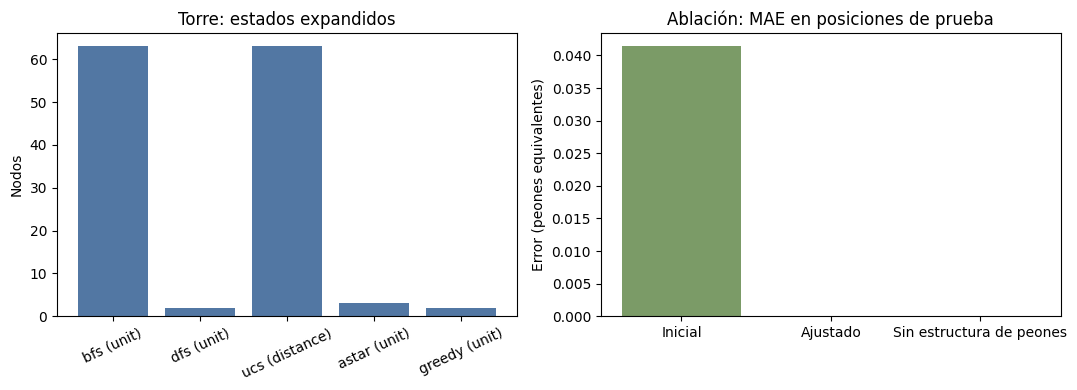

In [9]:

# INTEGRACIÓN A-C: búsquedas sobre la torre y ajuste local de pesos.
# El microproblema es cooperativo: cualquier movimiento de la torre acerca al objetivo.
from collections import deque
from heapq import heappush, heappop
from itertools import count
import matplotlib.pyplot as plt

ROOK_START = chess.parse_square("a1")
ROOK_GOAL = chess.parse_square("h8")


def rook_neighbors(square):
    """Genera destinos alcanzables en un movimiento de torre en tablero vacío."""
    file_index = chess.square_file(square)
    rank_index = chess.square_rank(square)
    destinations = []
    for f in range(8):
        if f != file_index:
            destinations.append(chess.square(f, rank_index))
    for r in range(8):
        if r != rank_index:
            destinations.append(chess.square(file_index, r))
    return destinations


def rook_step_cost(source, destination, cost_model):
    if cost_model == "unit":
        return 1
    if cost_model == "distance":
        return abs(chess.square_file(source) - chess.square_file(destination)) + abs(
            chess.square_rank(source) - chess.square_rank(destination)
        )
    raise ValueError(f"Modelo de costo desconocido: {cost_model}")


def rook_heuristic(square, mode):
    if mode == "unit_lines":
        if square == ROOK_GOAL:
            return 0
        same_line = (
            chess.square_file(square) == chess.square_file(ROOK_GOAL)
            or chess.square_rank(square) == chess.square_rank(ROOK_GOAL)
        )
        return 1 if same_line else 2
    if mode == "manhattan":
        return abs(chess.square_file(square) - chess.square_file(ROOK_GOAL)) + abs(
            chess.square_rank(square) - chess.square_rank(ROOK_GOAL)
        )
    return 0


def rook_search(strategy, cost_model="unit"):
    """Resuelve el problema e informa ruta, costo acumulado y expansiones."""
    heuristic = "unit_lines" if cost_model == "unit" else "manhattan"
    tie_breaker = count()
    frontier = []
    if strategy == "bfs":
        frontier = deque([(ROOK_START, 0, [ROOK_START])])
        discovered = {ROOK_START}
    elif strategy == "dfs":
        frontier = [(ROOK_START, 0, [ROOK_START])]
        discovered = {ROOK_START}
    else:
        start_priority = rook_heuristic(ROOK_START, heuristic) if strategy == "greedy" else 0
        heappush(frontier, (start_priority, next(tie_breaker), ROOK_START, 0, [ROOK_START]))
        best_cost = {ROOK_START: 0}

    expanded = 0
    while frontier:
        if strategy == "bfs":
            square, path_cost, path = frontier.popleft()
        elif strategy == "dfs":
            square, path_cost, path = frontier.pop()
        else:
            _, _, square, path_cost, path = heappop(frontier)
            if path_cost != best_cost.get(square):
                continue

        if square == ROOK_GOAL:
            return {
                "strategy": strategy,
                "cost_model": cost_model,
                "path": path,
                "moves": len(path) - 1,
                "cost": path_cost,
                "expanded": expanded,
            }

        expanded += 1
        for destination in rook_neighbors(square):
            edge_cost = rook_step_cost(square, destination, cost_model)
            new_cost = path_cost + edge_cost
            if strategy in ("bfs", "dfs"):
                if destination in discovered:
                    continue
                discovered.add(destination)
                frontier.append((destination, new_cost, path + [destination]))
                continue

            if strategy == "greedy":
                if destination in best_cost:
                    continue
                best_cost[destination] = new_cost
                priority = rook_heuristic(destination, heuristic)
            else:
                if new_cost >= best_cost.get(destination, float("inf")):
                    continue
                best_cost[destination] = new_cost
                priority = new_cost + rook_heuristic(destination, heuristic) if strategy == "astar" else new_cost
            heappush(frontier, (priority, next(tie_breaker), destination, new_cost, path + [destination]))

    raise RuntimeError("No se encontró una ruta al destino.")


rook_results = [
    rook_search("bfs", "unit"),
    rook_search("dfs", "unit"),
    rook_search("ucs", "distance"),
    rook_search("astar", "unit"),
    rook_search("greedy", "unit"),
]
for result in rook_results:
    algebraic_path = [chess.square_name(square) for square in result["path"]]
    print(
        f"{result['strategy']:>6} | costo={result['cost']:>2} | movimientos={result['moves']} "
        f"| expandidos={result['expanded']:>2} | ruta={' -> '.join(algebraic_path)}"
    )
assert rook_search("bfs", "unit")["moves"] == 2
assert rook_search("astar", "unit")["moves"] == 2
assert rook_search("ucs", "distance")["cost"] == 14

# Entrenamiento local pequeño: los objetivos son el balance material conocido,
# solo como proxy didáctico; no se interpretan como resultados de fuerza de juego.
WEIGHT_KEYS = ("material", "pawn_structure", "king_safety", "mobility")
WEIGHT_TRAIN_FENS = [
    "4k3/8/8/8/8/8/4P3/4K3 w - - 0 1",
    "4k3/8/8/8/8/8/3PP3/4K3 w - - 0 1",
    "4k3/8/8/8/8/8/3P4/4K3 w - - 0 1",
    "4k3/8/8/8/8/8/5P2/4K3 w - - 0 1",
    "4k3/8/8/8/8/8/4p3/4K3 w - - 0 1",
    "4k3/8/8/8/8/8/3pp3/4K3 w - - 0 1",
]
WEIGHT_TEST_FENS = [
    "4k3/8/8/8/8/8/2P1P3/4K3 w - - 0 1",
    "4k3/8/8/8/8/8/4p3/3K4 w - - 0 1",
]


def weight_examples(fens):
    examples = []
    feature_evaluator = Evaluator()
    for fen in fens:
        board = chess.Board(fen)
        features = {
            "material": feature_evaluator._material_score(board) / 100.0,
            "pawn_structure": feature_evaluator._pawn_structure_score(board) / 100.0,
            "king_safety": feature_evaluator._king_safety_score(board) / 100.0,
            "mobility": feature_evaluator._mobility_score(board) / 100.0,
        }
        target = feature_evaluator._material_score(board) / 100.0
        examples.append((features, target))
    return examples


train_examples = weight_examples(WEIGHT_TRAIN_FENS)
test_examples = weight_examples(WEIGHT_TEST_FENS)


def weight_loss(weights, examples):
    return sum(
        (sum(weights[key] * features[key] for key in WEIGHT_KEYS) - target) ** 2
        for features, target in examples
    ) / len(examples)


def local_weight_search(initial_weights, examples, budget=96):
    """Búsqueda local por coordenadas, con presupuesto máximo de 96 candidatos."""
    current = dict(initial_weights)
    best_loss = weight_loss(current, examples)
    evaluations = 1
    for step in (0.25, 0.10, 0.05):
        improved = True
        while improved and evaluations < budget:
            improved = False
            for key in WEIGHT_KEYS:
                for delta in (-step, step):
                    if evaluations >= budget:
                        break
                    candidate = dict(current)
                    candidate[key] = min(2.0, max(0.0, candidate[key] + delta))
                    candidate_loss = weight_loss(candidate, examples)
                    evaluations += 1
                    if candidate_loss + 1e-12 < best_loss:
                        current, best_loss = candidate, candidate_loss
                        improved = True
                if evaluations >= budget:
                    break
    return current, evaluations


initial_weights = {"material": 1.0, "pawn_structure": 0.30, "king_safety": 0.25, "mobility": 0.20}
tuned_weights, weight_evaluations = local_weight_search(initial_weights, train_examples)
print()
print("Pesos iniciales:", initial_weights)
print("Pesos finales:", tuned_weights, f"(evaluaciones de candidatos: {weight_evaluations})")
print("MAE de prueba inicial/final:",
      f"{weight_loss(initial_weights, test_examples) ** 0.5:.3f} / {weight_loss(tuned_weights, test_examples) ** 0.5:.3f}")

# Ablación: quitar la estructura de peones manteniendo iguales los demás pesos.
ablated_weights = dict(tuned_weights)
ablated_weights["pawn_structure"] = 0.0
print("MAE de prueba con ablación de estructura de peones:",
      f"{weight_loss(ablated_weights, test_examples) ** 0.5:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = [f"{r['strategy']} ({r['cost_model']})" for r in rook_results]
axes[0].bar(labels, [r["expanded"] for r in rook_results], color="#5277a3")
axes[0].set_title("Torre: estados expandidos")
axes[0].set_ylabel("Nodos")
axes[0].tick_params(axis="x", labelrotation=25)
error_labels = ["Inicial", "Ajustado", "Sin estructura de peones"]
error_values = [weight_loss(w, test_examples) ** 0.5 for w in (initial_weights, tuned_weights, ablated_weights)]
axes[1].bar(error_labels, error_values, color="#7b9b67")
axes[1].set_title("Ablación: MAE en posiciones de prueba")
axes[1].set_ylabel("Error (peones equivalentes)")
fig.tight_layout()
plt.show()



### D. Incertidumbre, garantías y ajedrez con información incompleta

**OR/AND para mate forzado.** En los nodos OR el atacante necesita encontrar al menos una jugada que fuerce el mate. En los nodos AND, correspondientes a la defensa, la prueba solo se sostiene si *todas* las respuestas legales del defensor permiten mantener el mate. La búsqueda de abajo implementa esta condición para una profundidad de mate indicada; se valida en una posición de mate en uno. Un resultado falso a esa profundidad no demuestra que no exista mate más adelante.

**Expectiminimax.** El ejemplo siguiente usa utilidades entre menos diez y más diez y un nodo de azar con probabilidades explícitas. Minimax ordinario trata erróneamente el azar como si eligiera la peor salida; expectiminimax calcula la esperanza ponderada.

**Kriegspiel.** En Kriegspiel el agente no observa la posición completa del rival ni todas sus piezas. Debe mantener una creencia/distribución sobre estados posibles y actualizarla con la información parcial del árbitro (por ejemplo, si una jugada fue bloqueada o si se dio jaque). Nuestro agente actual consulta el tablero completo, `piece_map()` y la lista exacta de jugadas legales; esa información no estaría disponible en el mismo formato. Las reglas clásicas de las actividades anteriores no se alteran: el azar aquí es solo un árbol de decisión aparte.


In [10]:

# Búsqueda AND-OR para comprobar mate forzado hasta una profundidad en plies.
def forced_mate(board, attacker, plies):
    outcome = board.outcome(claim_draw=False)
    if outcome is not None:
        return outcome.winner == attacker, {"terminal": outcome.result()}
    if plies <= 0:
        return False, None

    moves = list(board.legal_moves)
    if board.turn == attacker:
        # OR: basta una jugada que mantenga la prueba de mate.
        for move in moves:
            child = board.copy(stack=True)
            child.push(move)
            proven, subtree = forced_mate(child, attacker, plies - 1)
            if proven:
                return True, {"move": move.uci(), "children": [subtree]}
        return False, None

    # AND: toda defensa legal debe permitir que el atacante complete la prueba.
    if not moves:
        return False, None
    defense_proofs = []
    for move in moves:
        child = board.copy(stack=True)
        child.push(move)
        proven, subtree = forced_mate(child, attacker, plies - 1)
        if not proven:
            return False, None
        defense_proofs.append({"defense": move.uci(), "proof": subtree})
    return True, {"defenses": defense_proofs}


mate_board = chess.Board("7k/8/5KQ1/8/8/8/8/8 w - - 0 1")
mate_proven, mate_tree = forced_mate(mate_board, chess.WHITE, plies=1)
assert mate_proven
winning_move = chess.Move.from_uci(mate_tree["move"])
checkmate_board = mate_board.copy(stack=True)
checkmate_board.push(winning_move)
assert checkmate_board.is_checkmate()
print("OR/AND: mate en uno probado con", winning_move.uci(), "y", checkmate_board.legal_moves.count(), "defensas legales.")


def expectiminimax(node):
    kind = node["type"]
    if kind == "terminal":
        return node["value"]
    if kind == "max":
        return max(expectiminimax(child) for child in node["children"])
    if kind == "min":
        return min(expectiminimax(child) for child in node["children"])
    if kind == "chance":
        return sum(probability * expectiminimax(child) for probability, child in node["outcomes"])
    raise ValueError(f"Tipo de nodo desconocido: {kind}")


chance_tree = {
    "type": "max",
    "children": [
        {"type": "chance", "outcomes": [(0.5, {"type": "terminal", "value": 10}),
                                            (0.5, {"type": "terminal", "value": -8})]},
        {"type": "terminal", "value": 0.5},
    ],
}
expectiminimax_value = expectiminimax(chance_tree)
ordinary_minimax_value = max(min(10, -8), 0.5)
print("Expectiminimax (riesgosa=1.0, segura=0.5):", expectiminimax_value)
print("Minimax tratando el azar como adversario:", ordinary_minimax_value)
assert abs(expectiminimax_value - 1.0) < 1e-9
assert abs(ordinary_minimax_value - 0.5) < 1e-9
print("Fase 7: torre, ajuste local, AND-OR y expectiminimax verificados.")


OR/AND: mate en uno probado con g6g7 y 0 defensas legales.
Expectiminimax (riesgosa=1.0, segura=0.5): 1.0
Minimax tratando el azar como adversario: 0.5
Fase 7: torre, ajuste local, AND-OR y expectiminimax verificados.


## 8. Pruebas de corrección
El paquete de posiciones siguiente es un punto de partida. Las expectativas se deben verificar mediante reglas y análisis, sin asumir que siempre exista una única mejor jugada. Añadan al menos dos posiciones propias con justificación.

| Caso | Criterio |
|---|---|
| Inicial | 20 movimientos legales |
| Enroque | Ambos enroques blancos disponibles en la posición dada |
| Promoción | Cuatro promociones legales de a7 a a8 |
| Captura al paso | e5d6 legal y captura al paso |
| Mate en uno | El agente debe elegir alguna jugada que deje mate |
| Mate terminal | Sin decisión nueva, utilidad de derrota para negras |
| Ahogado | Tablas sin estar en jaque |
| Repetición | Reclamo detectable desde una historia construida |

A igual profundidad y evaluación, minimax y alfa-beta deben coincidir en valor. Las jugadas pueden diferir por empate. Una búsqueda debe dejar intactos FEN y pila de movimientos del tablero recibido. Si se interrumpe, ese invariante sigue aplicando.


In [11]:
POSITIONS = {
    "initial": "rnbqkbnr/pppppppp/8/8/8/8/PPPPPPPP/RNBQKBNR w KQkq - 0 1",
    "castling": "r3k2r/8/8/8/8/8/8/R3K2R w KQkq - 0 1",
    "promotion": "7k/P7/8/8/8/8/8/7K w - - 0 1",
    "en_passant": "7k/8/8/3pP3/8/8/8/7K w - d6 0 2",
    "mate_in_one": "7k/8/5KQ1/8/8/8/8/8 w - - 0 1",
    "checkmate": "7k/6Q1/5K2/8/8/8/8/8 b - - 0 1",
    "stalemate": "7k/5K2/6Q1/8/8/8/8/8 b - - 0 1",
    # Posiciones propias: una obliga a encontrar una evasion; la otra prueba un final con torre.
    "check_evasion": "4k3/8/8/8/8/8/4r3/4K3 w - - 0 1",
    "rook_endgame": "4k3/8/8/8/8/8/R7/4K3 w - - 0 1",
}
if READY:
    for name,fen in POSITIONS.items():
        b=chess.Board(fen)
        assert b.is_valid(), (name,b.status())
        print(name,"movimientos legales:",b.legal_moves.count())
    assert chess.Board(POSITIONS["initial"]).legal_moves.count()==20
    assert chess.Move.from_uci("e1g1") in chess.Board(POSITIONS["castling"]).legal_moves
    assert chess.Move.from_uci("e1c1") in chess.Board(POSITIONS["castling"]).legal_moves
    assert chess.Board(POSITIONS["checkmate"]).is_checkmate()
    assert chess.Board(POSITIONS["stalemate"]).is_stalemate()
    repetition=chess.Board()
    for uci in ["g1f3","g8f6","f3g1","f6g8"]*2:
        repetition.push_uci(uci)
    assert repetition.can_claim_threefold_repetition()
    print("Reglas de las posiciones base verificadas.")


initial movimientos legales: 20
castling movimientos legales: 26
promotion movimientos legales: 7
en_passant movimientos legales: 5
mate_in_one movimientos legales: 23
checkmate movimientos legales: 0
stalemate movimientos legales: 0
check_evasion movimientos legales: 3
rook_endgame movimientos legales: 19
Reglas de las posiciones base verificadas.


In [12]:

# PRUEBAS DE CORRECCION DE FASE 8

# Comprueba los dos escenarios propios y la consistencia de todos los FEN.
for name, fen in POSITIONS.items():
    position = chess.Board(fen)
    assert position.is_valid(), (name, position.status())
assert chess.Board(POSITIONS["check_evasion"]).is_check()
assert not chess.Board(POSITIONS["rook_endgame"]).is_check()

# Los seis agentes deben proponer una jugada legal en posiciones no terminales.
agents = [
    RandomAgent(),
    GreedyAgent(),
    MinimaxAgent(max_depth=2),
    AlphaBetaAgent(max_depth=2),
    OrderedAlphaBetaAgent(max_depth=3),
    MCTSAgent(max_rollouts=24, playout_limit=12),
]
legal_positions = [
    chess.Board(POSITIONS["initial"]),
    chess.Board(POSITIONS["check_evasion"]),
    chess.Board(POSITIONS["promotion"]),
    chess.Board(POSITIONS["rook_endgame"]),
]
for agent in agents:
    for position in legal_positions:
        decision = agent.choose(position, time_limit_s=0.20, seed=17)
        assert decision.move in position.legal_moves, (agent.name, position.fen(), decision)
print("Legalidad: los seis agentes devolvieron jugadas legales en cuatro posiciones.")

# Una victoria inmediata de mate es preferible a cualquier heuristica no terminal.
mate_in_one = chess.Board(POSITIONS["mate_in_one"])
for agent in [MinimaxAgent(max_depth=1), AlphaBetaAgent(max_depth=1),
              OrderedAlphaBetaAgent(max_depth=1)]:
    decision = agent.choose(mate_in_one, time_limit_s=1.0, seed=3)
    assert decision.move in mate_in_one.legal_moves
    child = mate_in_one.copy(stack=True)
    child.push(decision.move)
    assert child.is_checkmate(), (agent.name, decision.move)
print("Tactica: minimax, alfa-beta y alfa-beta ordenado encuentran mate en uno.")

# Una respuesta a jaque tiene que quitar el ataque al rey propio.
evasion = chess.Board(POSITIONS["check_evasion"])
for agent in agents:
    decision = agent.choose(evasion, time_limit_s=0.20, seed=19)
    child = evasion.copy(stack=True)
    child.push(decision.move)
    assert not child.is_attacked_by(chess.BLACK, child.king(chess.WHITE)), agent.name
print("Jaque: todos los agentes encuentran una evasion legal.")

# Las busquedas no deben alterar ni la posicion ni la historia entregadas.
history_board = chess.Board()
for uci in ["e2e4", "e7e5", "g1f3", "b8c6"]:
    history_board.push_uci(uci)
original_fen = history_board.fen()
original_stack = list(history_board.move_stack)
for agent in agents:
    agent.choose(history_board, time_limit_s=0.20, seed=23)
    assert history_board.fen() == original_fen
    assert history_board.move_stack == original_stack
print("Invariante: las busquedas normales conservaron FEN e historial.")

# Un plazo casi agotado debe conservar una jugada legal y no mutar el tablero.
for agent in [MinimaxAgent(max_depth=8), AlphaBetaAgent(max_depth=8),
              OrderedAlphaBetaAgent(max_depth=8), MCTSAgent(max_rollouts=10000)]:
    decision = agent.choose(history_board, time_limit_s=0.001, seed=29)
    assert decision.move in history_board.legal_moves, (agent.name, decision)
    assert history_board.fen() == original_fen
    assert history_board.move_stack == original_stack
print("Interrupcion cooperativa: jugada legal y estado intacto al agotar el plazo.")

# Con rollouts fijos y tiempo suficiente, la semilla reproduce la decision MCTS.
fixed_mcts = MCTSAgent(max_rollouts=32, playout_limit=12)
mcts_a = fixed_mcts.choose(history_board, time_limit_s=5.0, seed=101)
mcts_b = fixed_mcts.choose(history_board, time_limit_s=5.0, seed=101)
assert mcts_a.move == mcts_b.move
assert mcts_a.stats.simulations == mcts_b.stats.simulations == 32
print("MCTS: misma semilla y 32 simulaciones producen la misma jugada.")

# En un nodo del rival, UCT debe preferir el resultado menos favorable a la raiz.
root_color = chess.WHITE
opponent_board = chess.Board()
opponent_board.turn = chess.BLACK
opponent_node = MCTSNode(opponent_board)
root_favorable = MCTSNode(opponent_board.copy(), parent=opponent_node)
root_favorable.visits, root_favorable.total_value = 10, 9.0
root_unfavorable = MCTSNode(opponent_board.copy(), parent=opponent_node)
root_unfavorable.visits, root_unfavorable.total_value = 10, 1.0
opponent_node.children = [root_favorable, root_unfavorable]
opponent_node.visits = 20
assert opponent_node.best_child(exploration=0.0, root_color=root_color) is root_unfavorable
print("UCT: el turno del rival minimiza la recompensa de la raiz.")

# Los estados terminales no reciben jugada nueva y conservan la utilidad reglamentaria.
checkmated = chess.Board(POSITIONS["checkmate"])
stalemated = chess.Board(POSITIONS["stalemate"])
assert MinimaxAgent().choose(checkmated, time_limit_s=0.1, seed=0).move is None
assert utility_terminal(checkmated) == 1_000_000.0
assert utility_terminal(stalemated) == 0.0
print("Terminales: mate sin nueva jugada y ahogado con utilidad cero.")
print("Fase 8: todas las pruebas de correccion pasaron.")


Legalidad: los seis agentes devolvieron jugadas legales en cuatro posiciones.
Tactica: minimax, alfa-beta y alfa-beta ordenado encuentran mate en uno.
Jaque: todos los agentes encuentran una evasion legal.
Invariante: las busquedas normales conservaron FEN e historial.
Interrupcion cooperativa: jugada legal y estado intacto al agotar el plazo.
MCTS: misma semilla y 32 simulaciones producen la misma jugada.
UCT: el turno del rival minimiza la recompensa de la raiz.
Terminales: mate sin nueva jugada y ahogado con utilidad cero.
Fase 8: todas las pruebas de correccion pasaron.


## 9. Protocolo experimental y torneo
### Experimento 1: ahorro de búsqueda
Usen cinco posiciones intermedias válidas con distinto carácter: captura, jaque, defensa, posición tranquila y final. Comparen minimax, alfa-beta natural y alfa-beta ordenado a profundidades 1, 2 y 3 con evaluación fija. Mantengan el mismo árbol y condiciones de corte. Muestren valores y métricas; separen el tiempo de ordenar del tiempo total si lo instrumentan.

### Experimento 2: fuerza de juego bajo presupuesto
Torneo de los seis agentes, todos contra todos. Cada par juega al menos **cuatro partidas**, dos con cada color, desde posiciones iniciales/aperturas equilibradas y con semillas distintas. Son 60 partidas como mínimo. Compartan las mismas aperturas entre emparejamientos e intercambien colores. Usen, por ejemplo, un presupuesto de 0.2 segundos por decisión ajustado a su hardware y un límite de 160 plies. Si un algoritmo de profundidad fija excede el presupuesto, registren el exceso y apliquen una política uniforme documentada.

Puntuación reglamentaria: victoria 1, tablas 0.5 y derrota 0. Un límite artificial produce “truncada”: reporten su proporción por separado y dejen su resultado oficial sin asignar. Pueden presentar una clasificación provisional de partidas terminadas con la cobertura de cada agente; no den tablas ni victorias por evaluación estática como si fueran resultados oficiales.

### Experimento 3: ablación
Comparen una mejora con su versión base manteniendo los demás factores fijos. Por ejemplo, alfa-beta con/sin ordenación o evaluación con pesos iniciales/ajustados. Si comparan quietud con ausencia de quietud a igual profundidad, aclaren que el árbol ya no es el mismo.

### Experimento 4: MCTS
Repitan un conjunto de tácticas con al menos tres presupuestos de simulación y cinco semillas. Reporten tasa de acierto táctico, media y dispersión temporal. Una curva de mejora promedio no implica mejora monótona por semilla.

**Reporte mínimo:** nodos, hojas, podas, profundidad completada, tiempo por jugada, simulaciones, resultados, excesos y truncamientos. Para comparar fuerza use presupuesto temporal; para estudiar alfa-beta use profundidad fija. Para reproducibilidad exacta de MCTS use simulaciones fijas, porque un plazo temporal depende de la máquina.


Experimento 1: nodos/hojas/podas por posición, algoritmo y profundidad.
captura    minimax               d=1 nodos=    0 hojas=    6 podas=   0 tiempo=0.0000s valor=502.80
captura    alpha_beta_natural    d=1 nodos=    0 hojas=    6 podas=   0 tiempo=0.0160s valor=502.80
captura    alpha_beta_ordenado   d=1 nodos=    0 hojas=    6 podas=   0 tiempo=0.0000s valor=502.80
captura    minimax               d=2 nodos=    6 hojas=   59 podas=   0 tiempo=0.0620s valor=502.60
captura    alpha_beta_natural    d=2 nodos=    6 hojas=   15 podas=   5 tiempo=0.0160s valor=502.60
captura    alpha_beta_ordenado   d=2 nodos=    6 hojas=   15 podas=   5 tiempo=0.0310s valor=502.60
captura    minimax               d=3 nodos=   65 hojas=  706 podas=   0 tiempo=1.2500s valor=503.40
captura    alpha_beta_natural    d=3 nodos=   25 hojas=  172 podas=  14 tiempo=0.1880s valor=503.40
captura    alpha_beta_ordenado   d=3 nodos=   21 hojas=   97 podas=  12 tiempo=0.0940s valor=503.40
jaque      minimax          

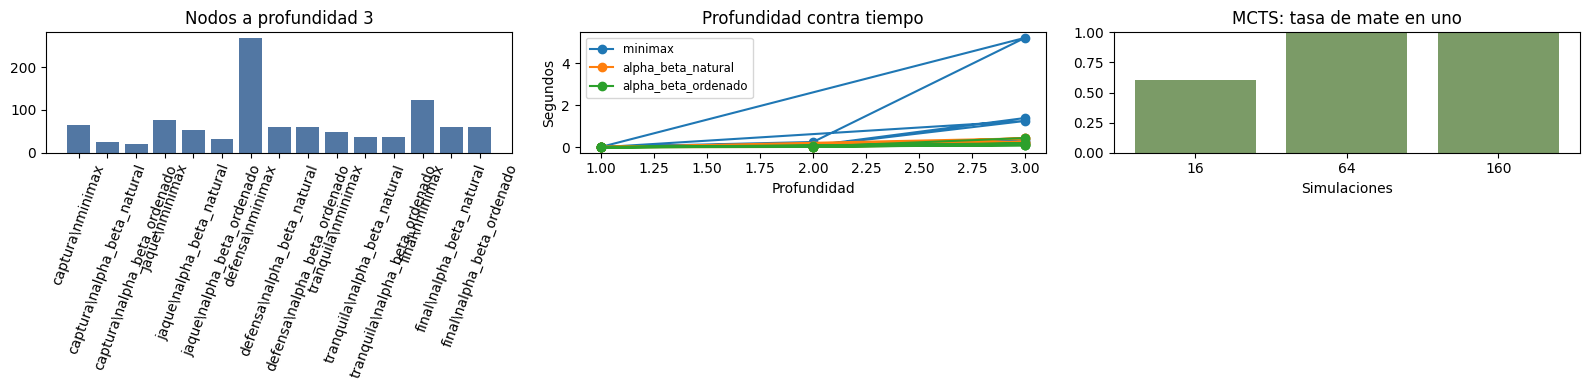

In [13]:

# EXPERIMENTOS DE FASE 9: búsqueda fija, MCTS y torneo reproducible.
import csv
import itertools
import json
import sys
from pathlib import Path
import statistics
import time
import chess.pgn
import matplotlib.pyplot as plt

CSV_FIELDS = ["game_id", "opening_id", "seed", "white_agent", "black_agent", "agent", "ply",
              "move_uci", "nodes", "leaves", "cutoffs", "completed_depth", "elapsed_s",
              "simulations", "time_exceeded", "termination", "official_result"]
GAME_CSV_FIELDS = ["game_id", "opening_id", "seed", "white_agent", "black_agent", "plies",
                   "termination", "official_result", "truncated", "time_exceeded",
                   "white_elapsed_mean_s", "black_elapsed_mean_s"]

# Cinco posiciones intermedias etiquetadas por su carácter táctico/estratégico.
def board_after(moves):
    board = chess.Board()
    for uci in moves:
        board.push_uci(uci)
    return board

EXPERIMENT_POSITIONS = {
    "captura": chess.Board("4k3/8/8/8/4r3/8/4R3/4K3 w - - 0 1"),
    "jaque": chess.Board("4k3/8/8/8/8/8/4R3/4K3 b - - 0 1"),
    "defensa": chess.Board("r3k3/8/8/8/8/8/R7/4K3 w - - 0 1"),
    "tranquila": chess.Board("4k3/8/8/8/8/8/P7/4K3 w - - 0 1"),
    "final": chess.Board("4k3/8/8/8/8/8/R7/4K3 w - - 0 1"),
}
for label, position in EXPERIMENT_POSITIONS.items():
    assert position.is_valid(), (label, position.status())


def run_search_comparison(depths=(1, 2, 3), time_limit_s=30.0):
    """Compara el mismo horizonte y evaluador; descarta resultados incompletos."""
    rows = []
    searchers = {
        "minimax": lambda depth: MinimaxAgent(max_depth=depth),
        "alpha_beta_natural": lambda depth: AlphaBetaAgent(max_depth=depth),
        "alpha_beta_ordenado": lambda depth: OrderedAlphaBetaAgent(max_depth=depth),
    }
    for position_name, position in EXPERIMENT_POSITIONS.items():
        baseline_scores = {}
        for depth in depths:
            for algorithm, factory in searchers.items():
                agent = factory(depth)
                decision = agent.choose(position.copy(stack=True), time_limit_s=time_limit_s, seed=5)
                if decision.stats.completed_depth != depth:
                    raise TimeoutError(
                        f"{algorithm} no completó profundidad {depth} en {position_name}; "
                        "aumente el presupuesto y repita."
                    )
                row = {
                    "position": position_name,
                    "algorithm": algorithm,
                    "depth": depth,
                    "score": decision.score,
                    "move_uci": decision.move.uci() if decision.move else "",
                    "nodes": decision.stats.nodes,
                    "leaves": decision.stats.leaves,
                    "cutoffs": decision.stats.cutoffs,
                    "completed_depth": decision.stats.completed_depth,
                    "elapsed_s": decision.stats.elapsed_s,
                }
                rows.append(row)
                if algorithm == "minimax":
                    baseline_scores[depth] = decision.score
                elif abs(decision.score - baseline_scores[depth]) > 1e-6:
                    raise AssertionError(
                        f"Valores de raíz distintos en {position_name}, profundidad {depth}: "
                        f"minimax={baseline_scores[depth]}, {algorithm}={decision.score}"
                    )
    return rows


search_comparison = run_search_comparison()
print("Experimento 1: nodos/hojas/podas por posición, algoritmo y profundidad.")
for row in search_comparison:
    print("{position:10s} {algorithm:21s} d={depth} nodos={nodes:5d} hojas={leaves:5d} "
          "podas={cutoffs:4d} tiempo={elapsed_s:.4f}s valor={score:.2f}".format(**row))

# Ablación controlada de ordenación: mismo horizonte, evaluación y posiciones.
ABLATION_DEPTH = 2



def make_tournament_agents():
    """Construye seis agentes independientes con configuración documentada."""
    return {
        "aleatorio": lambda: RandomAgent(),
        "voraz": lambda: GreedyAgent(),
        "minimax": lambda: MinimaxAgent(max_depth=3),
        "alfa_beta": lambda: AlphaBetaAgent(max_depth=3),
        "alfa_beta_ordenado": lambda: OrderedAlphaBetaAgent(max_depth=4),
        "mcts": lambda: MCTSAgent(max_rollouts=80, playout_limit=32),
    }


# Aperturas compartidas por todos los emparejamientos; se alternan colores.
TOURNAMENT_OPENINGS = {
    "inicial": chess.Board(),
    "italiana": board_after(["e2e4", "e7e5", "g1f3", "b8c6", "f1c4"]),
    "dama": board_after(["d2d4", "d7d5", "c2c4", "e7e6"]),
}


def run_tournament(*, games_per_pair=4, time_limit_s=0.20, max_plies=160,
                   seed=2026, csv_path=None, games_csv_path=None, pgn_path=None, config_path=None):
    """Corre todos contra todos, exporta cada decisión y cada partida.

    Cada partida limitada por max_plies se etiqueta como truncada y no recibe
    resultado oficial. Los agentes se ejecutan cooperativamente: cualquier
    exceso se registra al retorno y la política uniforme es continuar la partida
    con la jugada legal recibida, sin conceder una derrota automática.
    """
    if games_per_pair < 4 or games_per_pair % 2:
        raise ValueError("games_per_pair debe ser par y al menos cuatro para balancear colores.")
    if max_plies <= 0 or time_limit_s <= 0:
        raise ValueError("max_plies y time_limit_s deben ser positivos.")

    factories = make_tournament_agents()
    names = list(factories)
    move_rows, game_rows, pgn_games = [], [], []
    game_id = 0
    pairings = list(itertools.combinations(names, 2))
    for pair_index, (first_name, second_name) in enumerate(pairings):
        for game_number in range(games_per_pair):
            game_id += 1
            opening_names = list(TOURNAMENT_OPENINGS)
            opening_id = opening_names[(pair_index + game_number) % len(opening_names)]
            game_board = TOURNAMENT_OPENINGS[opening_id].copy(stack=True)
            if game_number % 2 == 0:
                white_name, black_name = first_name, second_name
            else:
                white_name, black_name = second_name, first_name
            agents = {chess.WHITE: factories[white_name](), chess.BLACK: factories[black_name]()}
            game_seed = seed + game_id
            game = chess.pgn.Game()
            game.headers["Event"] = "Torneo de agentes IA - Fase 9"
            game.headers["Site"] = "Local"
            game.headers["Round"] = str(game_id)
            game.headers["White"] = white_name
            game.headers["Black"] = black_name
            game.headers["Opening"] = opening_id
            game.headers["Seed"] = str(game_seed)
            game.setup(game_board)
            node = game
            ply_count = 0
            total_elapsed = {white_name: [], black_name: []}
            any_exceeded = False

            while game_board.outcome(claim_draw=True) is None and ply_count < max_plies:
                color = game_board.turn
                agent_name = white_name if color == chess.WHITE else black_name
                before_fen = game_board.fen()
                started = time.monotonic()
                decision = agents[color].choose(game_board.copy(stack=True),
                                                time_limit_s=time_limit_s,
                                                seed=game_seed + ply_count)
                measured = time.monotonic() - started
                elapsed = max(measured, decision.stats.elapsed_s)
                exceeded = elapsed > time_limit_s
                any_exceeded = any_exceeded or exceeded
                total_elapsed[agent_name].append(elapsed)
                if decision.move is None or decision.move not in game_board.legal_moves:
                    raise ValueError(f"{agent_name} devolvió una jugada ausente/ilegal en {before_fen}.")

                move_rows.append({
                    "game_id": game_id, "opening_id": opening_id, "seed": game_seed,
                    "white_agent": white_name, "black_agent": black_name,
                    "agent": agent_name, "ply": ply_count + 1,
                    "move_uci": decision.move.uci(), "nodes": decision.stats.nodes,
                    "leaves": decision.stats.leaves, "cutoffs": decision.stats.cutoffs,
                    "completed_depth": decision.stats.completed_depth,
                    "elapsed_s": elapsed, "simulations": decision.stats.simulations,
                    "time_exceeded": exceeded, "termination": "", "official_result": "",
                })
                game_board.push(decision.move)
                node = node.add_variation(decision.move)
                ply_count += 1

            outcome = game_board.outcome(claim_draw=True)
            truncated = outcome is None
            termination = "ply_limit" if truncated else outcome.termination.name
            result = "*" if truncated else outcome.result()
            game.headers["Termination"] = termination
            game.headers["Result"] = result
            official_result = None if truncated else result
            game_rows.append({
                "game_id": game_id, "opening_id": opening_id, "seed": game_seed,
                "white_agent": white_name, "black_agent": black_name, "plies": ply_count,
                "termination": termination, "official_result": official_result,
                "truncated": truncated, "time_exceeded": any_exceeded,
                "white_elapsed_mean_s": statistics.fmean(total_elapsed[white_name]) if total_elapsed[white_name] else 0.0,
                "black_elapsed_mean_s": statistics.fmean(total_elapsed[black_name]) if total_elapsed[black_name] else 0.0,
            })
            pgn_games.append(game)

    if csv_path:
        with open(csv_path, "w", newline="", encoding="utf-8") as output:
            writer = csv.DictWriter(output, fieldnames=CSV_FIELDS)
            writer.writeheader()
            writer.writerows(move_rows)
    if games_csv_path:
        with open(games_csv_path, "w", newline="", encoding="utf-8") as output:
            writer = csv.DictWriter(output, fieldnames=GAME_CSV_FIELDS)
            writer.writeheader()
            writer.writerows(game_rows)
    if pgn_path:
        with open(pgn_path, "w", encoding="utf-8") as output:
            for game in pgn_games:
                print(game, file=output, end="\n\n")
    configuration = {
        "games_per_pair": games_per_pair,
        "time_limit_s": time_limit_s,
        "max_plies": max_plies,
        "seed": seed,
        "agent_names": names,
        "agent_settings": {"minimax_depth": 3, "alpha_beta_depth": 3,
                           "ordered_alpha_beta_depth": 4, "mcts_rollouts": 80,
                           "mcts_playout_limit": 32},
        "openings": list(TOURNAMENT_OPENINGS),
        "python_version": sys.version,
        "python_chess_version": chess.__version__,
        "time_overrun_policy": "record overrun and continue with the legal move; no automatic forfeit",
    }
    if config_path:
        with open(config_path, "w", encoding="utf-8") as output:
            json.dump(configuration, output, ensure_ascii=False, indent=2)
    return {"games": game_rows, "moves": move_rows, "pgn": pgn_games,
            "configuration": configuration}


def tournament_summary(tournament):
    """Devuelve resultados oficiales y truncamientos sin asignar puntos ficticios."""
    summary = {}
    for name in tournament["configuration"]["agent_names"]:
        finished = [g for g in tournament["games"]
                    if not g["truncated"] and name in (g["white_agent"], g["black_agent"])]
        truncated = [g for g in tournament["games"]
                     if g["truncated"] and name in (g["white_agent"], g["black_agent"])]
        wins = draws = losses = 0
        for game in finished:
            is_white = game["white_agent"] == name
            result = game["official_result"]
            if result == "1/2-1/2":
                draws += 1
            elif (result == "1-0") == is_white:
                wins += 1
            else:
                losses += 1
        summary[name] = {"finished": len(finished), "wins": wins, "draws": draws,
                         "losses": losses, "truncated": len(truncated),
                         "points": wins + 0.5 * draws,
                         "mean_time_s": statistics.fmean(
                             row["elapsed_s"] for row in tournament["moves"]
                             if name == row["agent"]
                         ) if tournament["moves"] else 0.0}
    return summary


# Ablación del orden: mismos estados, profundidad, límite y evaluador.
ABLATION_ROWS = []
for position_name, position in EXPERIMENT_POSITIONS.items():
    base = AlphaBetaAgent(max_depth=ABLATION_DEPTH).choose(position.copy(stack=True), time_limit_s=30.0, seed=9)
    ordered = OrderedAlphaBetaAgent(max_depth=ABLATION_DEPTH).choose(position.copy(stack=True), time_limit_s=30.0, seed=9)
    assert base.stats.completed_depth == ordered.stats.completed_depth == ABLATION_DEPTH
    assert abs(base.score - ordered.score) < 1e-6
    ABLATION_ROWS.append({"position": position_name, "natural_nodes": base.stats.nodes,
                          "ordered_nodes": ordered.stats.nodes,
                          "natural_cutoffs": base.stats.cutoffs,
                          "ordered_cutoffs": ordered.stats.cutoffs})
print("Ablación de ordenación (mismo valor de raíz):", ABLATION_ROWS)

# MCTS táctico con tres presupuestos fijos y cinco semillas; éxito significa
# que la jugada elegida produce mate inmediato en la posición mate_en_uno.
TACTICAL_BOARD = chess.Board("7k/8/5KQ1/8/8/8/8/8 w - - 0 1")
MCTS_BUDGETS = (16, 64, 160)
MCTS_SEEDS = (3, 11, 23, 41, 59)
mcts_experiment = []
for budget in MCTS_BUDGETS:
    for experiment_seed in MCTS_SEEDS:
        agent = MCTSAgent(max_rollouts=budget, playout_limit=32)
        decision = agent.choose(TACTICAL_BOARD.copy(stack=True), time_limit_s=20.0, seed=experiment_seed)
        child = TACTICAL_BOARD.copy(stack=True)
        child.push(decision.move)
        mcts_experiment.append({"budget": budget, "seed": experiment_seed,
                                "success": child.is_checkmate(),
                                "elapsed_s": decision.stats.elapsed_s,
                                "simulations": decision.stats.simulations})
print("MCTS por presupuesto:")
for budget in MCTS_BUDGETS:
    sample = [r for r in mcts_experiment if r["budget"] == budget]
    times = [r["elapsed_s"] for r in sample]
    print(f"{budget:3d} simulaciones: aciertos={sum(r['success'] for r in sample)}/{len(sample)}, "
          f"tiempo medio={statistics.fmean(times):.4f}s, "
          f"desv.={statistics.pstdev(times):.4f}s")

# El torneo completo exige 60 partidas y no se ejecuta al cargar el cuaderno.
# Torneo completo: run_tournament(csv_path='torneo_movimientos.csv',
#     games_csv_path='torneo_partidas.csv', pgn_path='torneo.pgn',
#     config_path='torneo_config.json').
# Esta prueba piloto solo verifica formato/contabilidad, no es un resultado oficial.
tournament_pilot = run_tournament(games_per_pair=4, time_limit_s=0.05, max_plies=4, seed=2026)
assert len(tournament_pilot["games"]) == 60
assert all(game["truncated"] and game["official_result"] is None for game in tournament_pilot["games"])
print("Piloto de torneo: 60 partidas emparejadas, todas truncadas a 4 plies; resultados oficiales no asignados.")
print("Configuración del torneo completo:", {"games_per_pair": 4, "partidas": 60,
      "time_limit_s": 0.20, "max_plies": 160, "aperturas": list(TOURNAMENT_OPENINGS)})

# Gráficas solicitadas: nodos por algoritmo, profundidad/tiempo y acierto MCTS.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
depth_three = [row for row in search_comparison if row["depth"] == 3]
axes[0].bar([f"{r['position']}\\n{r['algorithm']}" for r in depth_three],
            [r["nodes"] for r in depth_three], color="#5277a3")
axes[0].set_title("Nodos a profundidad 3")
axes[0].tick_params(axis="x", labelrotation=70)
for algorithm in ("minimax", "alpha_beta_natural", "alpha_beta_ordenado"):
    rows = [r for r in search_comparison if r["algorithm"] == algorithm]
    axes[1].plot([r["depth"] for r in rows], [r["elapsed_s"] for r in rows], marker="o", label=algorithm)
axes[1].set_title("Profundidad contra tiempo")
axes[1].set_xlabel("Profundidad")
axes[1].set_ylabel("Segundos")
axes[1].legend(fontsize="small")
axes[2].bar([str(b) for b in MCTS_BUDGETS],
            [sum(r["success"] for r in mcts_experiment if r["budget"] == b) / len(MCTS_SEEDS)
             for b in MCTS_BUDGETS], color="#7b9b67")
axes[2].set_title("MCTS: tasa de mate en uno")
axes[2].set_xlabel("Simulaciones")
axes[2].set_ylim(0, 1)
fig.tight_layout()
plt.show()


### Tablas para completar con el torneo completo

Se ejecutó el torneo completo: seis agentes, cuatro partidas por pareja con colores alternados, presupuesto de 0.05 s por decisión, máximo de 160 plies y semilla base 2026. De las 60 partidas, 53 terminaron con resultado reglamentario y 7 llegaron al límite artificial; estas últimas se reportan como truncadas y no reciben puntos. La política uniforme ante excesos de tiempo fue registrar el exceso y continuar con la jugada legal, sin derrota automática.
| Agente | Puntos / partidas terminadas | Victorias | Tablas | Derrotas | Truncadas | Tiempo medio |
|---|---|---|---|---|---|---|
| Aleatorio | 3.5 / 13 | 1 | 5 | 7 | 7 | 0.0018 s |
| Voraz | 15.5 / 20 | 12 | 7 | 1 | 0 | 0.0534 s |
| Minimax | 8.5 / 18 | 1 | 15 | 2 | 2 | 0.0642 s |
| Alfa-beta | 8.0 / 18 | 0 | 16 | 2 | 2 | 0.0638 s |
| Alfa-beta mejorado | 11.5 / 19 | 5 | 13 | 1 | 1 | 0.0680 s |
| MCTS | 6.0 / 18 | 1 | 10 | 7 | 2 | 0.0630 s |

Incluyan barras de nodos por algoritmo y posición, curvas de profundidad contra tiempo y tasa de éxito de MCTS por presupuesto. No comparen números de “nodos” de implementaciones con definiciones distintas sin explicarlo.


## 10. Cronograma propuesto
| Días | Hito verificable |
|---|---|
| 1–2 | PEAS, contratos, reglas y tablero gráfico funcionando |
| 3–4 | Aleatorio, voraz, evaluación y pruebas de perspectiva |
| 5–6 | Minimax y alfa-beta con equivalencia de valor |
| 7–8 | Iterative deepening, plazo e integración de modos |
| 9–10 | MCTS y mejora adicional |
| 11–12 | Integraciones de capítulos 3–4 y experimentos |
| 13–14 | Análisis, limpieza del cuaderno y sustentación |

No aumenten la profundidad hasta verificar legalidad, restauración del estado y tratamiento de terminales. Diseñen el torneo primero con dos agentes y una partida corta.


## 11. Rúbrica · 100 puntos
| Criterio | Puntos | Evidencia |
|---|---:|---|
| Formulación, PEAS y arquitectura | 10 | Modelo, contratos y justificación |
| Interfaz y reglas | 15 | Tres modos, controles, turnos y pruebas especiales |
| Seis agentes | 30 | Aleatorio 2, voraz 3, minimax 6, alfa-beta 6, mejorado 6, MCTS 7 |
| Integración de capítulos 3–4 | 10 | Torre, búsqueda informada/local e incertidumbre |
| Mejora adicional y ablación | 10 | Comparación controlada y explicación |
| Experimentos reproducibles | 15 | Torneo, métricas, semillas, PGN y CSV |
| Informe y sustentación individual | 10 | Interpretación y modificación de código en vivo |
| **Total** | **100** | |

Conversión sugerida a escala de 0 a 5: puntos/20, sujeta a las reglas de evaluación del docente. La existencia de una interfaz vistosa no reemplaza la implementación de búsqueda. Los resultados inventados no cuentan como experimentos.

### Uso de herramientas y autoría
Declaren librerías, fuentes y ayudas de IA utilizadas. Cada integrante debe explicar el código, ejecutar una prueba nueva y modificar una decisión del algoritmo durante la sustentación. No se exige ocultar las herramientas usadas; se exige comprender y verificar lo entregado.


## 12. Informe final, sustentación y conclusiones

### Síntesis de resultados observados

- En cinco posiciones y profundidades 1–3, minimax, alfa-beta natural y alfa-beta ordenado devolvieron el mismo valor de raíz. En la posición de captura a profundidad 3 se expandieron 65 nodos con minimax, 25 con alfa-beta natural y 21 con ordenación; en el final, 123 frente a 60 y 60. El orden de jugadas puede cambiar la cantidad de poda, no el valor minimax cuando el árbol y la evaluación son iguales.
- En el torneo de 60 partidas, 53 terminaron por una condición reglamentaria y 7 llegaron al límite de 160 plies. Las truncadas no recibieron resultado ni puntos. La tabla informa puntos solo de partidas terminadas.
- El presupuesto fue 0,05 s por jugada. Se excedió en 3.385 de 5.014 decisiones (67,5 %): 100 % de decisiones de minimax, alfa-beta y MCTS; 32,7 % del voraz y 0,2 % del aleatorio. Por tanto, este torneo describe los agentes con la política de continuar tras el exceso, pero no demuestra una comparación bajo cumplimiento estricto del presupuesto.
- En la táctica de mate en uno, MCTS acertó 3/5 con 16 simulaciones y 5/5 con 64 y 160. Es evidencia de una sola posición con cinco semillas, no una conclusión general sobre fuerza ni una tendencia garantizada por semilla.
- El ajuste local obtuvo error cuadrático medio de prueba menor al optimizar contra una etiqueta que representa balance material. Es una demostración didáctica del procedimiento, no una evaluación de fuerza ajedrecística; las posiciones son pocas y deben ampliarse antes de generalizar.

### Respuestas para la sustentación

1. El voraz puntúa el resultado inmediato de cada jugada y no representa explícitamente una respuesta del adversario; minimax compara continuaciones alternando maximizador y minimizador. Para la sustentación, muestre una posición táctica concreta y reproduzca ambas decisiones; las pruebas automatizadas de este cuaderno verifican mate en uno y evasión de jaque, no una victoria general del minimax sobre el voraz.
2. Una poda se justifica cuando el mejor valor garantizado de un nodo ya es al menos tan bueno como el límite que el ancestro permite. En la prueba de profundidad 3 se registraron 37 cortes en la posición de captura con alfa-beta natural y 12 con ordenación; el orden altera dónde se poda, pero no el valor de raíz.
3. Si varias jugadas empatan en valor, el orden de enumeración o de exploración puede seleccionar una distinta. La propiedad que se compara es el valor minimax, no necesariamente la jugada en empates.
4. La evaluación está expresada desde blancas. Invertir solo el signo en una parte del algoritmo puede hacer que negras maximicen la ventaja blanca o que el terminal se interprete al revés. Se debe transformar la perspectiva de forma consistente en selección, hojas y terminales.
5. Minimax y alfa-beta conservan la última iteración completa y una jugada legal de respaldo. Alfa-beta ordenado entrega la última profundidad terminada y registra la profundidad; el presupuesto es cooperativo, no puede interrumpir una función bloqueada.
6. MCTS almacena recompensas desde el color de la raíz. Al seleccionar un nodo cuyo turno corresponde al rival, invierte el término de explotación, de modo que el rival prefiera resultados menos favorables a la raíz.
7. Un FEN aislado no conserva la secuencia necesaria para detectar repetición. Las copias de búsqueda usan `board.copy(stack=True)` para preservar el historial.
8. En el problema de la torre se supone que no hay rival ni piezas que bloqueen. Con oposición, las acciones del otro jugador pueden cambiar el estado y una ruta geométrica cooperativa no prueba que exista una estrategia ganadora.
9. La separación entrenamiento/prueba ayuda, pero dos posiciones de prueba no permiten descartar sobreajuste. Se debe ampliar el conjunto y fijarlo antes de ajustar; los pesos actuales solo optimizan un proxy de material.
10. La evidencia disponible son resultados oficiales, cobertura, truncamientos, tiempos, nodos y simulaciones con semilla y configuración registradas. En este experimento hubo muchos excesos de tiempo, por lo que cualquier afirmación de superioridad debe limitarse a este torneo y su política, no a una comparación estricta de presupuesto.

### Conclusión técnica

Durante la integración se detectó que alfa-beta inicialmente reutilizaba minimax y no podaba; también se corrigió la selección UCT para que el turno del rival minimice la recompensa de la raíz. Las pruebas comparan valores a igual profundidad, comprueban podas y ensayan una respuesta del oponente. En el torneo la limitación más visible fue temporal: con profundidad fija, búsqueda cooperativa y 0,05 s por decisión, muchos turnos excedieron el plazo. La mejora siguiente sería aplicar una política estricta y uniforme de tiempo (o una búsqueda que se detenga en iteraciones completas) antes de usar los puntos del torneo como comparación de fuerza.


## Lista final de entrega

- [x] Cuaderno único con agentes, tablero SVG, controlador, pruebas y experimentos.
- [x] Resultados reproducibles del torneo: `torneo_fase9_partidas.csv`, `torneo_fase9_movimientos.csv`, `torneo_fase9.pgn` y `torneo_fase9_config.json`.
- [x] Entorno probado: Python 3.12.3 y `python-chess` 1.11.2; dependencias de interfaz y gráficos indicadas en la sección 1.
- [x] Declaración de fuentes y apoyo de IA en la sección inicial.

### Referencias
- Russell y Norvig, *AIMA*, 4.ª edición, capítulos 2–5. [Índice oficial](https://aima.cs.berkeley.edu/contents.html).
- [python-chess: reglas y estados](https://python-chess.readthedocs.io/en/latest/core.html).
- [python-chess: SVG](https://python-chess.readthedocs.io/en/latest/svg.html).
- [python-chess: PGN](https://python-chess.readthedocs.io/en/latest/pgn.html).
- [ipywidgets: documentación](https://ipywidgets.readthedocs.io/en/stable/).
